# CIC-IoT-2023 — Full Data Analysis Notebook
**Dataset:** `lacg030175/CIC-IoT-2023` (Hugging Face) — 1.34 M network flows, 39 numeric features, 3 label columns.

**Contents**
0. Setup & configuration
1. Loading the data
2. General information (shape, types, memory, preview)
3. **Data quality / "failures"** (missing, infinite, negative, duplicates, inconsistencies, conflicting labels, leakage between splits)
4. Descriptive statistics (min, max, median, mean, quantiles, MAD, skew, kurtosis, ...)
5. Target analysis (class balance)
6. Univariate analysis (distributions, boxplots)
7. Bivariate / multivariate analysis (correlation, per-class profiles, VIF)
8. Statistical tests (normality, Mann-Whitney, Kruskal-Wallis, chi-square, drift between splits / PSI)
9. Outlier analysis (IQR, z-score, modified z-score, Isolation Forest, LOF)
10. **Temporal / time analysis** (IAT, Rate, window size, burstiness, row-order tests, ACF, ADF, spectrum, CUSUM)
11. Advanced analysis (PCA, t-SNE, clustering, hierarchical clustering, feature importance, ML models, error analysis, cross-validation)
12. Final summary & export

> ⚠️ **Important note about time:** the dataset has **no timestamp column** and the authors state it has no natural temporal ordering
> (it was subsampled per attack type and shuffled). Section 10 therefore analyses the *time-related features* (`IAT`, `Rate`, `Number`, derived duration/throughput)
> and tests whether row order carries any temporal structure. It does **not** pretend to rebuild a real calendar time series.

> **What "failures" means here:** (a) data-quality defects (section 3), (b) share of attack traffic (section 5), (c) model misclassification errors — false positives / false negatives (section 11).

## 0. Setup & configuration

In [1]:
# Run this cell once if a package is missing (then restart the kernel):
# %pip install -q datasets pandas pyarrow numpy scipy matplotlib seaborn scikit-learn statsmodels

In [2]:
import os, json, time, warnings, math
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.6g}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# ---------------- CONFIGURATION (lower these if your PC is slow / low on RAM) ----------------
SEED           = 42
SAMPLE_N       = 50_000     # sample used for heavy plots / tests
MODEL_TRAIN_N  = 200_000    # rows from the train split used to train ML models
TSNE_N         = 8_000      # rows for t-SNE
HF_NAME        = "lacg030175/CIC-IoT-2023"
HF_CONFIG      = "random_3way"   # 80/10/10 split (train / test / validation)
OUT            = "outputs"       # all tables are exported here
# --------------------------------------------------------------------------------------------
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)
report = {}   # key numbers collected along the notebook, exported at the end


def save_table(df_, name):
    path = os.path.join(OUT, f"{name}.csv")
    df_.to_csv(path)
    print(f"[saved] {path}")


def slog(x):
    # signed log1p : tames heavy-tailed features for PCA / clustering / linear models
    return np.sign(x) * np.log1p(np.abs(x))

## 1. Loading the data

In [3]:
t0 = time.time()
LOCAL = os.environ.get("CIC_LOCAL_PARQUET")   # optional: path to a local parquet (used for offline tests)

if LOCAL:
    df = pd.read_parquet(LOCAL)
    if "split" not in df.columns:
        df["split"] = "train"
else:
    from datasets import load_dataset
    ds = load_dataset(HF_NAME, HF_CONFIG)       # downloads ~134 MB of parquet the first time
    parts = []
    for split_name in ds.keys():
        part = ds[split_name].to_pandas()
        part["split"] = split_name
        parts.append(part)
    df = pd.concat(parts, ignore_index=True)
    del ds, parts

TARGETS  = [c for c in ["Label", "attack_class", "label"] if c in df.columns]
META     = ["split"]
FEATURES = [c for c in df.columns if c not in TARGETS + META]

FLAG_COLS     = [c for c in df.columns if c.endswith("_flag_number")]
PROTO_COLS    = [c for c in ["HTTP","HTTPS","DNS","Telnet","SMTP","SSH","IRC","TCP","UDP","DHCP","ARP","ICMP","IGMP","IPv","LLC"] if c in df.columns]
RATIO_COLS    = FLAG_COLS + PROTO_COLS            # these are expected to be in [0, 1]
COUNT_COLS    = [c for c in ["ack_count","syn_count","fin_count","rst_count"] if c in df.columns]
SIZE_COLS     = [c for c in ["Tot sum","Min","Max","AVG","Std","Tot size","Variance","Header_Length"] if c in df.columns]
TIME_COLS     = [c for c in ["IAT","Rate","Number","Time_To_Live"] if c in df.columns]

print(f"Loaded {len(df):,} rows x {df.shape[1]} columns in {time.time()-t0:.1f}s")
print(f"{len(FEATURES)} features | targets: {TARGETS} | splits: {df['split'].value_counts().to_dict()}")

Loaded 1,342,314 rows x 43 columns in 6.6s
39 features | targets: ['Label', 'attack_class', 'label'] | splits: {'train': 1073851, 'validation': 134232, 'test': 134231}


## 2. General information

In [4]:
print("Shape:", df.shape)
mem = df.memory_usage(deep=True).sum() / 1024**2
print(f"Memory usage: {mem:,.1f} MB")
print("\nDtype counts:\n", df.dtypes.astype(str).value_counts())
print("\nColumn groups:")
for name, cols in [("Flags", FLAG_COLS), ("Protocols", PROTO_COLS), ("Counts", COUNT_COLS), ("Sizes/stats", SIZE_COLS), ("Time-related", TIME_COLS)]:
    print(f"  {name:12s}: {cols}")
report["n_rows"] = int(len(df)); report["n_features"] = len(FEATURES); report["memory_mb"] = round(mem, 1)

Shape: (1342314, 43)
Memory usage: 473.6 MB

Dtype counts:
 float64    30
int64      10
str         3
Name: count, dtype: int64

Column groups:
  Flags       : ['fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number']
  Protocols   : ['HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC']
  Counts      : ['ack_count', 'syn_count', 'fin_count', 'rst_count']
  Sizes/stats : ['Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'Variance', 'Header_Length']
  Time-related: ['IAT', 'Rate', 'Number', 'Time_To_Live']


In [5]:
display(df.head(10))
display(df.tail(5))
display(df.sample(5, random_state=SEED))

,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,Label,attack_class,label,split
0,0,47,64,"5,779.75",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,59200,592,592,592,0,592,0.000173688,100,0,Mirai-greeth_flood,Mirai,1,train
1,10.2,6,63.36,"1,974.3",0,0.01,0.01,0,0.48,0,0,48,1,0,1,0,0.01,0,0,0,0,0,0.5,0,0,0.01,0,0,0.99,0.99,91192,60,1514,911.92,583.72,911.92,0.00050653,100,"340,729",DDoS-ACK_Fragmentation,DDoS,1,train
2,1,47,65.23,"2,090.53",0,0,0,0.01,0.02,0,0,2,0,0,0,0,0,0.03,0,0,0,0,0.02,0.03,0,0,0,0,1,1,56660,74,592,566.6,111.302,566.6,0.00048012,100,"12,388.2",Mirai-greeth_flood,Mirai,1,train
3,20.12,6,65.74,"26,639",0,0.99,0,0,0.01,0,0,1,99,0,0,0,0.01,0,0,0,0,0,1,0,0,0,0,0,1,1,6006,60,66,60.06,0.6,60.06,3.7539e-05,100,0.36,DDoS-SynonymousIP_Flood,DDoS,1,train
4,4,47,64.42,"1,854.66",0.01,0.09,0.01,0.01,0.02,0,0,2,9,1,1,0,0.1,0,0,0,0,0,0.11,0,0,0.02,0,0,0.98,0.98,51211,54,578,512.11,171.337,512.11,0.00054064,100,"29,356.2",Mirai-greip_flood,Mirai,1,train
5,8,17,64,"32,508.9",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,1,6000,60,60,60,0,60,3.07608e-05,100,0,DDoS-UDP_Flood,DDoS,1,train
6,0,1,64,"32,197",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,6000,60,60,60,0,60,3.10588e-05,100,0,DDoS-ICMP_Flood,DDoS,1,train
7,0,1,64,"30,949.7",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,6000,60,60,60,0,60,3.23105e-05,100,0,DDoS-ICMP_Flood,DDoS,1,train
8,0,1,64,"18,043.9",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,6000,60,60,60,0,60,5.54204e-05,100,0,DDoS-ICMP_Flood,DDoS,1,train
9,4,17,64,"1,859.4",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,0,0,0,0,1,1,93800,362,1514,938,578.902,938,0.000537829,100,"335,127",DDoS-UDP_Fragmentation,DDoS,1,train


,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,Label,attack_class,label,split
1342309,0,47,64,"3,067.2",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,59200,592,592,592,0,592,0.00032604,100,0,Mirai-greeth_flood,Mirai,1,validation
1342310,20,6,64,"6,253.53",0,1,0,0,0,0,0,0,100,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,6000,60,60,60,0,60,0.00015991,100,0,DDoS-SynonymousIP_Flood,DDoS,1,validation
1342311,37.6,6,111.2,"16,156.8",0,0,0,0,1,0,0,10,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,11884,94,1462,"1,188.4",576.799,"1,188.4",6.30856e-05,10,"332,698",DNS_Spoofing,Spoofing,1,validation
1342312,27.6,6,145.1,74.2986,0,0.2,0,0.2,0.7,0,0,7,2,0,0,0,0.7,0.1,0,0,0,0,0.8,0.2,0,0,0,0,1,1,1797,66,775,179.7,221.067,179.7,0.0158888,10,"48,870.5",BrowserHijacking,Web-based,1,validation
1342313,29.6,6,64,"1,147.33",0,0,0,0,0.9,0,0,9,0,0,0,0,0.9,0.1,0,0,0,0,0.9,0.1,0,0,0,0,1,1,13722,96,1514,"1,372.2",448.411,"1,372.2",0.000942993,10,"201,072",BenignTraffic,Benign,0,validation


,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,Label,attack_class,label,split
1166035,44.8,6,81.7,"12,164.5",0,0,0,0,1,0,0,10,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,4976,66,1462,497.6,665.547,497.6,8.74043e-05,10,"442,953",BenignTraffic,Benign,0,test
617839,23.2,6,64,"5,208.37",0,0.1,0,0,1,0,0,10,1,0,0,0,0.9,0,0,0,0.1,0,1,0,0,0,0,0,1,1,2048,60,1494,204.8,453,204.8,0.000192094,10,"205,209",DictionaryBruteForce,BruteForce,1,train
785089,27.2,6,93.6,447.225,0,0,0,0.2,0.8,0,0,8,0,0,0,0,0.6,0.2,0,0,0,0,0.8,0.2,0,0,0,0,1,1,6707,66,1514,670.7,726.629,670.7,0.0024492,10,"527,990",BenignTraffic,Benign,0,train
336828,8,17,64,"5,965.87",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,1,6000,60,60,60,0,60,0.000167909,100,0,DoS-UDP_Flood,DoS,1,train
1309990,28.4,6,112.5,42.0661,0.1,0,0,0.4,0.9,0,0,9,0,1,0,0.1,0.5,0,0,0,0,0,0.9,0.1,0,0,0,0,1,1,1123,66,214,112.3,60.0556,112.3,0.0237722,10,"3,606.68",BenignTraffic,Benign,0,validation


In [6]:
buf = pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.count(), "n_unique": df.nunique()})
display(buf)

,dtype,non_null,n_unique
Header_Length,float64,1342314,2244
Protocol Type,int64,1342314,6
Time_To_Live,float64,1342314,10916
Rate,float64,1342314,485529
fin_flag_number,float64,1342314,244
syn_flag_number,float64,1342314,385
rst_flag_number,float64,1342314,308
psh_flag_number,float64,1342314,422
ack_flag_number,float64,1342314,645
ece_flag_number,float64,1342314,24


## 3. Data quality — how many "failures" does the data contain?
We run **row-level checks** (each returns a boolean mask) and **column-level checks**. Checks are split into:
* **Hard defects** — values that should never happen (NaN, ±inf, negative sizes, `Min > Max`, ratios outside [0,1], label inconsistency, ...).
* **Informational** — duplicates and suspicious values (not necessarily errors in network flows, e.g. flood attacks produce near-identical flows).

In [7]:
X = df[FEATURES]
col_quality = pd.DataFrame({
    "dtype":     X.dtypes.astype(str),
    "missing":   X.isna().sum(),
    "missing_%": X.isna().mean() * 100,
    "inf":       np.isinf(X).sum(),
    "negative":  (X < 0).sum(),
    "zeros_%":   (X == 0).mean() * 100,
    "n_unique":  X.nunique(),
})
col_quality["constant"] = col_quality["n_unique"] <= 1
display(col_quality.sort_values("zeros_%", ascending=False))
print("Constant (zero-information) columns:", col_quality.index[col_quality["constant"]].tolist())
save_table(col_quality, "03_column_quality")

,dtype,missing,missing_%,inf,negative,zeros_%,n_unique,constant
SMTP,float64,0,0,0,0,99.9396,9,False
Telnet,float64,0,0,0,0,99.9357,10,False
IRC,float64,0,0,0,0,99.8798,11,False
cwr_flag_number,float64,0,0,0,0,99.8497,19,False
ece_flag_number,float64,0,0,0,0,99.7562,24,False
IGMP,float64,0,0,0,0,99.7308,17,False
SSH,float64,0,0,0,0,98.7472,26,False
DHCP,float64,0,0,0,0,98.5416,66,False
rst_count,int64,0,0,0,0,86.229,101,False
rst_flag_number,float64,0,0,0,0,86.229,308,False


Constant (zero-information) columns: []
[saved] outputs\03_column_quality.csv


In [8]:
# ---------------- Row-level checks ----------------
masks = {}
masks["Missing value (any feature)"]       = X.isna().any(axis=1)
masks["Infinite value (any feature)"]      = pd.Series(np.isinf(X).any(axis=1), index=df.index)
masks["Negative value (any feature)"]      = (X < 0).any(axis=1)
if RATIO_COLS:
    masks["Flag/protocol ratio outside [0,1]"] = ((df[RATIO_COLS] < 0) | (df[RATIO_COLS] > 1)).any(axis=1)
if {"Min","Max"} <= set(df.columns):
    masks["Min > Max"] = df["Min"] > df["Max"]
if {"Min","AVG","Max"} <= set(df.columns):
    masks["AVG outside [Min, Max]"] = (df["AVG"] < df["Min"] - 1e-6) | (df["AVG"] > df["Max"] + 1e-6)
if {"Std","Variance"} <= set(df.columns):
    masks["Variance != Std^2 (rtol 1e-3)"] = pd.Series(~np.isclose(df["Variance"].values, df["Std"].values ** 2, rtol=1e-3, atol=1e-6), index=df.index)
if {"Tot size","AVG"} <= set(df.columns):
    masks["Tot size != AVG (rtol 1e-3)"] = pd.Series(~np.isclose(df["Tot size"].values, df["AVG"].values, rtol=1e-3, atol=1e-6), index=df.index)
if {"Tot sum","AVG","Number"} <= set(df.columns):
    masks["Tot sum != AVG*Number (rtol 1e-3)"] = pd.Series(~np.isclose(df["Tot sum"].values, df["AVG"].values * df["Number"].values, rtol=1e-3, atol=1e-6), index=df.index)
if {"label","Label"} <= set(df.columns):
    masks["Binary label inconsistent with Label"] = (df["label"] == 0) != (df["Label"] == "BenignTraffic")

HARD = list(masks.keys())

# informational checks
masks["(info) Rate <= 0"] = df["Rate"] <= 0 if "Rate" in df.columns else pd.Series(False, index=df.index)
masks["(info) IAT <= 0"]  = df["IAT"] <= 0  if "IAT" in df.columns else pd.Series(False, index=df.index)

# hash each feature-vector once -> fast duplicates / conflicts / leakage checks
h = pd.util.hash_pandas_object(df[FEATURES], index=False).values
df_h = pd.DataFrame({"h": h, "Label": df["Label"].values, "split": df["split"].values})
masks["(info) Exact duplicate row (features+label)"] = pd.Series(df_h.duplicated(subset=["h", "Label"]).values, index=df.index)

n = len(df)
quality = pd.DataFrame({"rows_affected": {k: int(m.sum()) for k, m in masks.items()}})
quality["% of dataset"] = quality["rows_affected"] / n * 100
quality["type"] = ["hard defect" if k in HARD else "informational" for k in quality.index]
display(quality.sort_values("rows_affected", ascending=False))
save_table(quality, "03_row_quality_checks")

hard_any = pd.concat([masks[k] for k in HARD], axis=1).any(axis=1)
report["rows_with_hard_defect"] = int(hard_any.sum())
report["rows_with_hard_defect_pct"] = round(float(hard_any.mean() * 100), 4)
report["duplicate_rows"] = int(masks["(info) Exact duplicate row (features+label)"].sum())
report["duplicate_rows_pct"] = round(float(masks["(info) Exact duplicate row (features+label)"].mean() * 100), 3)
print(f"\nRows with at least ONE hard defect : {hard_any.sum():,} ({hard_any.mean()*100:.4f}%)")
print(f"Clean rows (no hard defect)        : {(~hard_any).sum():,} ({(~hard_any).mean()*100:.4f}%)")
print(f"Exact duplicate rows               : {report['duplicate_rows']:,} ({report['duplicate_rows_pct']:.3f}%)")

,rows_affected,% of dataset,type
(info) Exact duplicate row (features+label),115597,8.61177,informational
(info) IAT <= 0,1,7.44982e-05,informational
Negative value (any feature),1,7.44982e-05,hard defect
Missing value (any feature),0,0,hard defect
Infinite value (any feature),0,0,hard defect
Min > Max,0,0,hard defect
"Flag/protocol ratio outside [0,1]",0,0,hard defect
"AVG outside [Min, Max]",0,0,hard defect
Variance != Std^2 (rtol 1e-3),0,0,hard defect
Tot sum != AVG*Number (rtol 1e-3),0,0,hard defect


[saved] outputs\03_row_quality_checks.csv

Rows with at least ONE hard defect : 1 (0.0001%)
Clean rows (no hard defect)        : 1,342,313 (99.9999%)
Exact duplicate rows               : 115,597 (8.612%)


In [9]:
# ---------------- Label ambiguity: identical feature vectors with DIFFERENT labels ----------------
g = df_h.groupby("h")["Label"].nunique()
conflict_hashes = g[g > 1].index
conflict_mask = df_h["h"].isin(conflict_hashes).values
print(f"Distinct feature-vectors shared by >1 different Label : {len(conflict_hashes):,}")
print(f"Rows involved in label conflicts                      : {conflict_mask.sum():,} ({conflict_mask.mean()*100:.3f}%)")
report["label_conflict_rows"] = int(conflict_mask.sum())
report["label_conflict_rows_pct"] = round(float(conflict_mask.mean() * 100), 3)

if conflict_mask.any():
    top = (df.loc[conflict_mask].groupby("Label").size().sort_values(ascending=False).head(15)
           .rename("rows in conflict").to_frame())
    display(top)

# ---------------- Leakage / overlap between splits ----------------
splits = df["split"].unique().tolist()
if "train" in splits:
    train_hashes = set(df_h.loc[df_h["split"] == "train", "h"])
    leak = {}
    for s in splits:
        if s == "train":
            continue
        leak[s] = float(df_h.loc[df_h["split"] == s, "h"].isin(train_hashes).mean() * 100)
    print("\n% of rows in each split whose exact feature-vector also appears in TRAIN:")
    for s, v in leak.items():
        print(f"   {s:11s}: {v:.2f}%")
    report["split_leakage_pct"] = {k: round(v, 3) for k, v in leak.items()}

Distinct feature-vectors shared by >1 different Label : 21,126
Rows involved in label conflicts                      : 114,702 (8.545%)


,rows in conflict
Label,
DDoS-TCP_Flood,21325
DoS-TCP_Flood,20326
DDoS-SynonymousIP_Flood,17803
DDoS-SYN_Flood,15056
DDoS-UDP_Flood,15056
DoS-UDP_Flood,11223
DoS-SYN_Flood,7248
MITM-ArpSpoofing,2310
Recon-PortScan,1322



% of rows in each split whose exact feature-vector also appears in TRAIN:
   test       : 12.88%
   validation : 13.03%


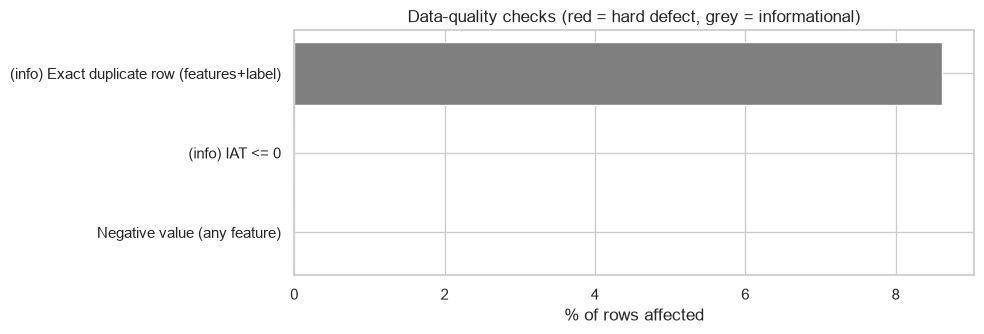

In [10]:
# ---------------- Visual summary of defects ----------------
plot_q = quality[quality["rows_affected"] > 0].sort_values("rows_affected")
if len(plot_q):
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(plot_q) + 2))
    colors = ["#d62728" if t == "hard defect" else "#7f7f7f" for t in plot_q["type"]]
    ax.barh(plot_q.index, plot_q["% of dataset"], color=colors)
    ax.set_xlabel("% of rows affected"); ax.set_title("Data-quality checks (red = hard defect, grey = informational)")
    plt.tight_layout(); plt.show()
else:
    print("No defect detected by any check.")

## 4. Descriptive statistics (min, max, median, mean, quantiles, MAD, skewness, kurtosis, ...)

In [11]:
def describe_full(d):
    d = d.replace([np.inf, -np.inf], np.nan)
    q = d.quantile([.01, .05, .25, .5, .75, .95, .99]).T
    q.columns = ["p01", "p05", "p25", "median", "p75", "p95", "p99"]
    out = pd.DataFrame({
        "count": d.count(), "missing": d.isna().sum(), "n_unique": d.nunique(),
        "mean": d.mean(), "std": d.std(), "min": d.min(),
    }).join(q).assign(max=d.max())
    out["range"]    = out["max"] - out["min"]
    out["IQR"]      = out["p75"] - out["p25"]
    out["MAD"]      = (d - d.median()).abs().median()
    out["CV"]       = out["std"] / out["mean"].replace(0, np.nan)
    out["skew"]     = d.skew()
    out["kurtosis"] = d.kurt()
    out["mode"]     = d.mode().iloc[0]
    out["zeros_%"]  = (d == 0).mean() * 100
    out["sum"]      = d.sum()
    return out

desc = describe_full(df[FEATURES])
display(desc)
save_table(desc, "04_descriptive_stats_all_features")

,count,missing,n_unique,mean,std,min,p01,p05,p25,median,p75,p95,p99,max,range,IQR,MAD,CV,skew,kurtosis,mode,zeros_%,sum
Header_Length,1342314,0,2244,17.4995,11.1964,0,0,0,8,20,26,32.8,42,60,60,18,9.92,0.639811,0.0287717,-0.702915,20,8.15249,2.34898e+07
Protocol Type,1342314,0,6,10.9853,11.2599,0,1,1,6,6,17,47,47,47,47,11,0,1.025,2.33269,4.79738,6,0.28056,1.47457e+07
Time_To_Live,1342314,0,10916,79.6254,34.4024,0,48,59.8,64,64,80.3,155.9,231,255,255,16.3,1.27,0.432053,2.63077,7.27032,64,0.0129627,1.06882e+08
Rate,1342314,0,485529,"16,151.4","50,031.3",2.14292e-05,22.6148,47.3042,277.739,"2,392.28","15,523.5","53,676.8","277,768",6.29146e+06,6.29146e+06,"15,245.8","2,320.87",3.09765,13.3073,533.865,"322,639",0,2.16802e+10
fin_flag_number,1342314,0,244,0.0129766,0.0439872,0,0,0,0,0,0,0.1,0.2,1,1,0,0,3.38975,5.06704,40.3286,0,86.1342,"17,418.6"
syn_flag_number,1342314,0,385,0.158463,0.32248,0,0,0,0,0,0.1,1,1,1,1,0.1,0,2.03505,1.97076,2.21563,0,63.3876,"212,706"
rst_flag_number,1342314,0,308,0.0411259,0.146714,0,0,0,0,0,0,0.3,0.9,1,1,0,0,3.56742,4.51162,21.7246,0,86.229,"55,203.9"
psh_flag_number,1342314,0,422,0.0828924,0.146834,0,0,0,0,0,0.1,0.4,0.6,1,1,0.1,0,1.77138,2.24026,5.89706,0,60.6039,"111,268"
ack_flag_number,1342314,0,645,0.351503,0.391394,0,0,0,0,0.1,0.71,1,1,1,1,0.71,0.1,1.11349,0.51654,-1.39188,0,39.1551,"471,827"
ece_flag_number,1342314,0,24,0.000176454,0.0053053,0,0,0,0,0,0,0,0,1,1,0,0,30.0663,52.8042,"4,478.19",0,99.7562,236.856


[saved] outputs\04_descriptive_stats_all_features.csv


In [12]:
# Quick "min / max / median" cheat-sheet
cheat = desc[["min", "median", "mean", "max", "std"]].copy()
cheat["argmax_row"] = [df[c].idxmax() for c in cheat.index]
cheat["argmin_row"] = [df[c].idxmin() for c in cheat.index]
display(cheat)

,min,median,mean,max,std,argmax_row,argmin_row
Header_Length,0,20,17.4995,60,11.1964,1835,0
Protocol Type,0,6,10.9853,47,11.2599,0,88
Time_To_Live,0,64,79.6254,255,34.4024,292,88
Rate,2.14292e-05,"2,392.28","16,151.4",6.29146e+06,"50,031.3",788871,120739
fin_flag_number,0,0,0.0129766,1,0.0439872,90354,0
syn_flag_number,0,0,0.158463,1,0.32248,10,0
rst_flag_number,0,0,0.0411259,1,0.146714,322,0
psh_flag_number,0,0,0.0828924,1,0.146834,2236,0
ack_flag_number,0,0.1,0.351503,1,0.391394,18,0
ece_flag_number,0,0,0.000176454,1,0.0053053,27098,0


In [13]:
# Highly skewed / heavy-tailed / dominated-by-zero features
display(desc.loc[desc["skew"].abs() > 2, ["skew", "kurtosis", "median", "max"]].sort_values("skew", key=abs, ascending=False).head(25))
print("Features with > 90% zeros:", desc.index[desc["zeros_%"] > 90].tolist())

,skew,kurtosis,median,max
IAT,896.873,"852,603",0.000438352,"46,665.2"
SMTP,96.8182,"13,289.7",0,0.6
Telnet,85.9234,"10,855.3",0,0.6
cwr_flag_number,63.2457,"7,979.88",0,1
IRC,56.9356,"5,940.32",0,0.7
ece_flag_number,52.8042,"4,478.19",0,1
IGMP,30.5648,"1,115.59",0,0.4
Variance,25.8612,"1,510.41","2,683.24",1.35848e+08
SSH,19.7742,449.057,0,1
DHCP,18.9967,443.887,0,0.8


Features with > 90% zeros: ['ece_flag_number', 'cwr_flag_number', 'Telnet', 'SMTP', 'SSH', 'IRC', 'DHCP', 'IGMP']


## 5. Target analysis (class balance)

In [14]:
def vc(col):
    t = df[col].value_counts().rename("rows").to_frame()
    t["%"] = t["rows"] / len(df) * 100
    return t

for col in ["label", "attack_class", "Label"]:
    if col in df.columns:
        print(f"\n===== {col} =====")
        display(vc(col))

n_attack = int((df["label"] == 1).sum()); n_benign = int((df["label"] == 0).sum())
print(f"\nAttack rows: {n_attack:,} ({n_attack/len(df)*100:.2f}%) | Benign rows: {n_benign:,} ({n_benign/len(df)*100:.2f}%) | imbalance ratio attack:benign = {n_attack/max(n_benign,1):.2f}:1")
lab_counts = df["Label"].value_counts()
print(f"Fine-grained labels: {lab_counts.size} | largest class {lab_counts.max():,} | smallest class {lab_counts.min():,} ({lab_counts.idxmin()}) | median class size {int(lab_counts.median()):,}")
report.update(attack_rows=n_attack, benign_rows=n_benign, attack_pct=round(n_attack/len(df)*100, 3),
              n_labels=int(lab_counts.size), n_attack_classes=int(df["attack_class"].nunique()),
              smallest_label=str(lab_counts.idxmin()), smallest_label_rows=int(lab_counts.min()))


===== label =====


,rows,%
label,,
1,1142326,85.1013
0,199988,14.8987



===== attack_class =====


,rows,%
attack_class,,
DDoS,452195,33.6877
Recon,202257,15.0678
DoS,199992,14.899
Benign,199988,14.8987
Mirai,149991,11.1741
Spoofing,99999,7.44975
Web-based,24828,1.84964
BruteForce,13064,0.973245



===== Label =====


,rows,%
Label,,
BenignTraffic,199988,14.8987
DDoS-SynonymousIP_Flood,50000,3.72491
DDoS-ICMP_Flood,50000,3.72491
MITM-ArpSpoofing,50000,3.72491
Recon-HostDiscovery,50000,3.72491
Recon-PortScan,50000,3.72491
Mirai-udpplain,49999,3.72484
DoS-TCP_Flood,49999,3.72484
DNS_Spoofing,49999,3.72484



Attack rows: 1,142,326 (85.10%) | Benign rows: 199,988 (14.90%) | imbalance ratio attack:benign = 5.71:1
Fine-grained labels: 32 | largest class 199,988 | smallest class 1,252 (Uploading_Attack) | median class size 49,997


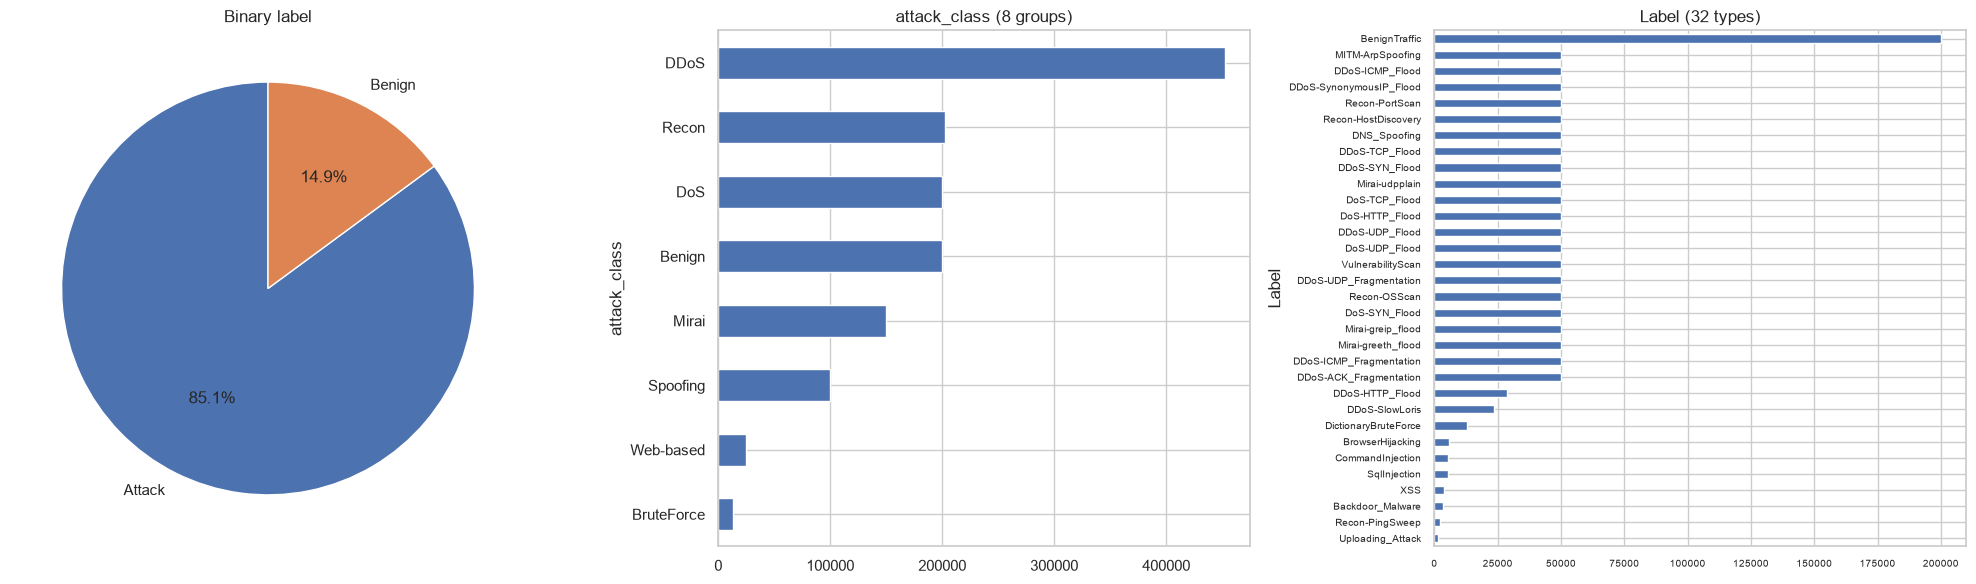

attack_class,Benign,BruteForce,DDoS,DoS,Mirai,Recon,Spoofing,Web-based
split,,,,,,,,
test,14.899,0.981,33.649,14.973,11.284,15.017,7.36,1.837
train,14.899,0.974,33.696,14.893,11.165,15.074,7.454,1.846
validation,14.899,0.961,33.663,14.876,11.135,15.065,7.507,1.894


attack_class,Benign,BruteForce,DDoS,DoS,Mirai,Recon,Spoofing,Web-based
Label,,,,,,,,
Backdoor_Malware,0,0,0,0,0,0,0,3218
BenignTraffic,199988,0,0,0,0,0,0,0
BrowserHijacking,0,0,0,0,0,0,0,5859
CommandInjection,0,0,0,0,0,0,0,5409
DDoS-ACK_Fragmentation,0,0,49993,0,0,0,0,0
DDoS-HTTP_Flood,0,0,28790,0,0,0,0,0
DDoS-ICMP_Flood,0,0,50000,0,0,0,0,0
DDoS-ICMP_Fragmentation,0,0,49994,0,0,0,0,0
DDoS-SYN_Flood,0,0,49999,0,0,0,0,0


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
df["label"].map({0: "Benign", 1: "Attack"}).value_counts().plot.pie(autopct="%1.1f%%", ax=axes[0], startangle=90); axes[0].set_ylabel(""); axes[0].set_title("Binary label")
vc("attack_class")["rows"].sort_values().plot.barh(ax=axes[1]); axes[1].set_title("attack_class (8 groups)")
lab_counts.sort_values().plot.barh(ax=axes[2], fontsize=7); axes[2].set_title(f"Label ({lab_counts.size} types)")
plt.tight_layout(); plt.show()

# Is the split stratified?
split_dist = pd.crosstab(df["split"], df["attack_class"], normalize="index") * 100
display(split_dist.round(3))
display(pd.crosstab(df["attack_class"], df["Label"]).T)

## 6. Univariate analysis

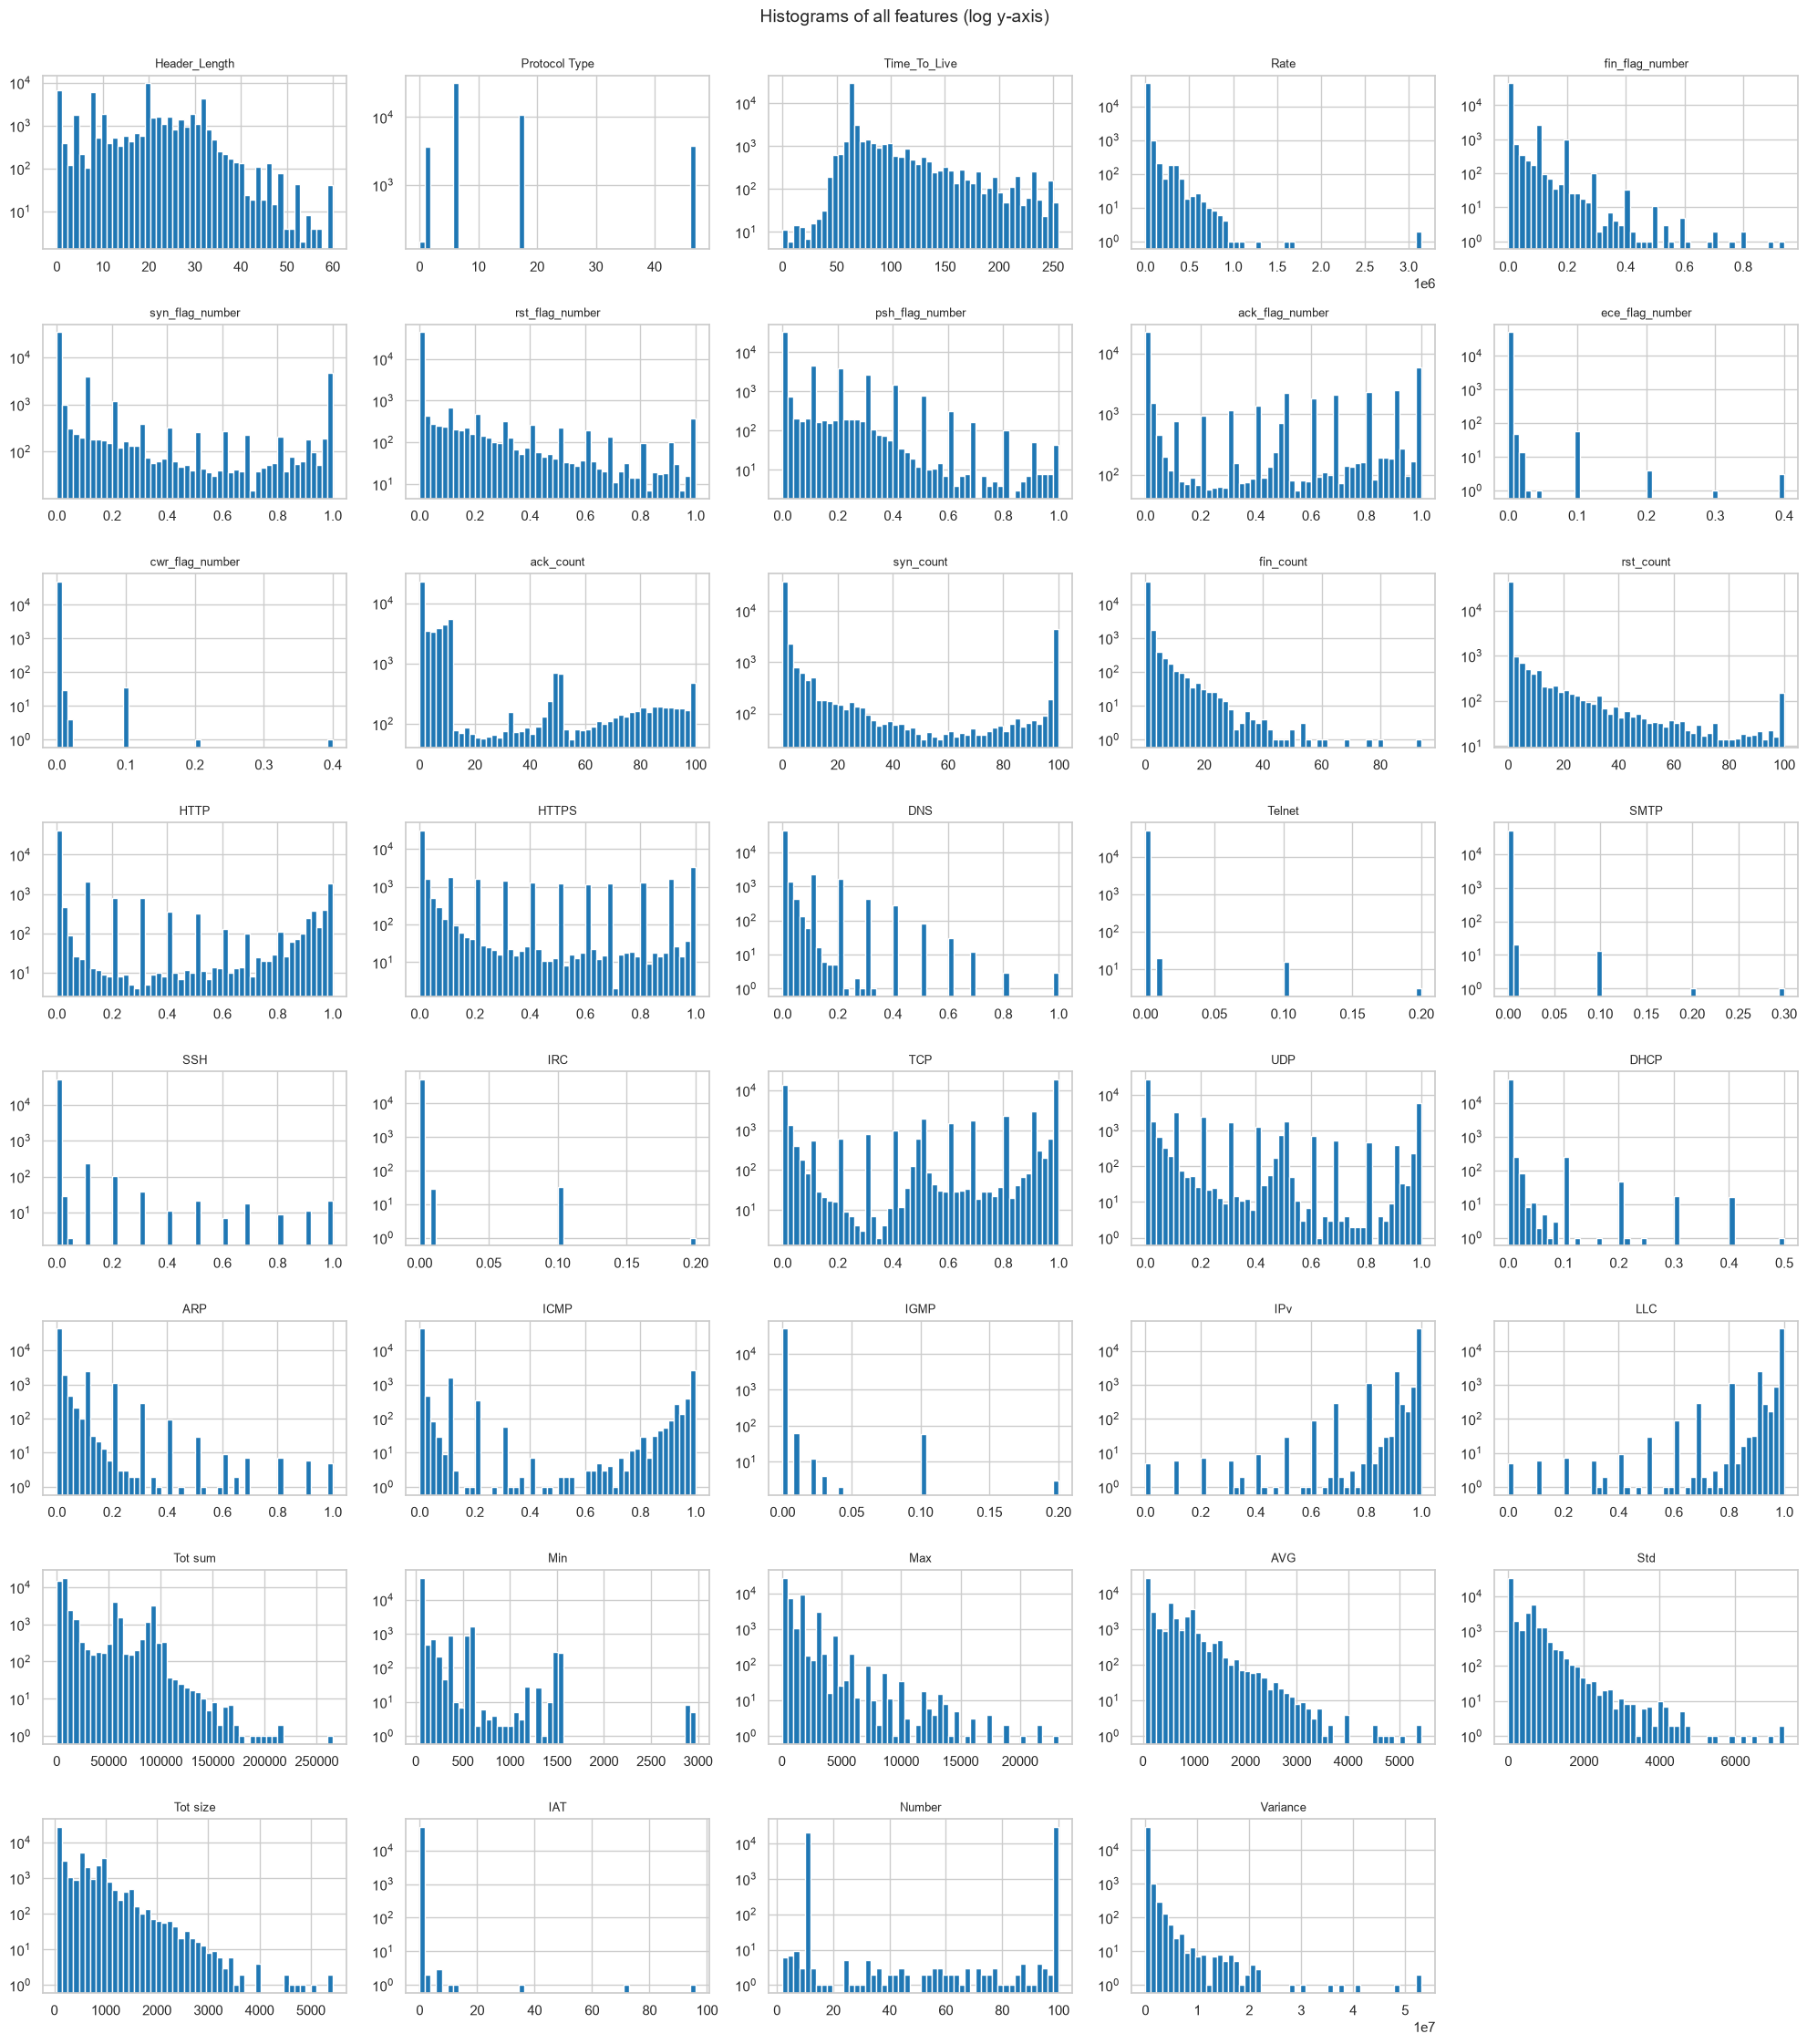

In [16]:
S = df.sample(min(SAMPLE_N, len(df)), random_state=SEED)   # working sample
varying = [c for c in FEATURES if S[c].nunique() > 1]

ncols = 5; nrows = math.ceil(len(varying) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows))
for ax, c in zip(axes.ravel(), varying):
    ax.hist(S[c].replace([np.inf, -np.inf], np.nan).dropna(), bins=50, color="#1f77b4", log=True)
    ax.set_title(c, fontsize=9)
for ax in axes.ravel()[len(varying):]:
    ax.axis("off")
fig.suptitle("Histograms of all features (log y-axis)", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

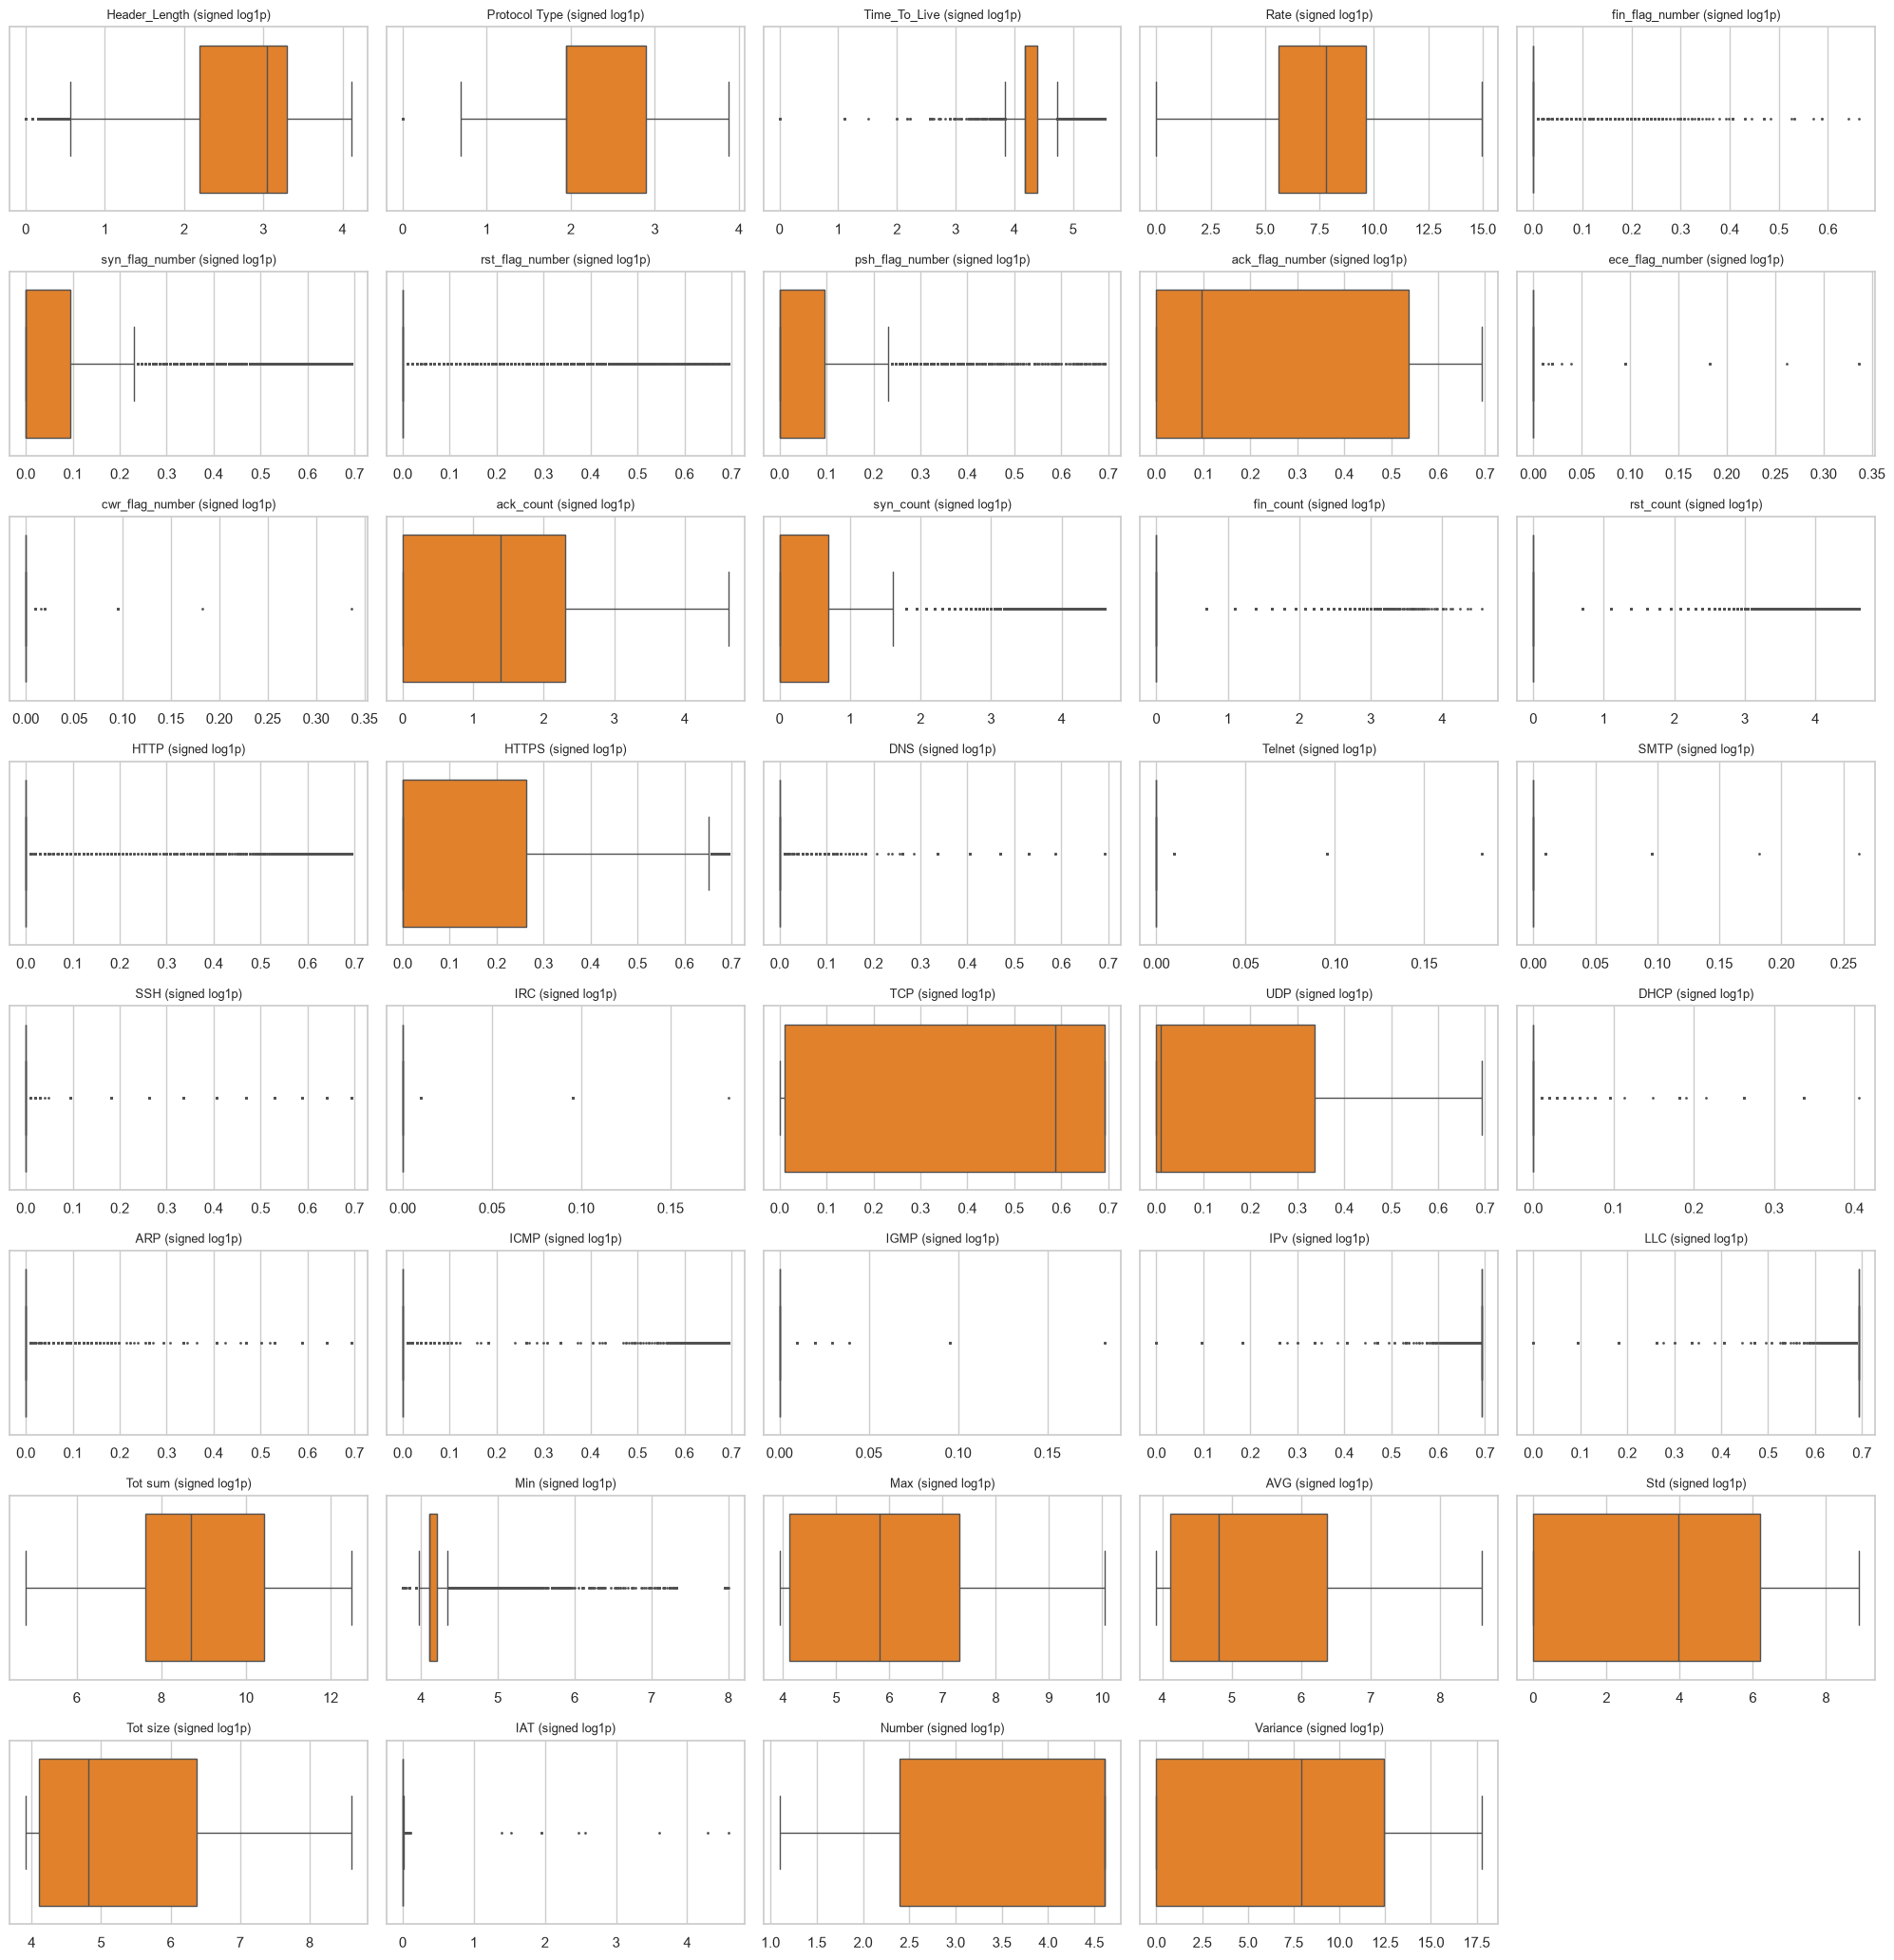

In [17]:
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows))
for ax, c in zip(axes.ravel(), varying):
    sns.boxplot(x=slog(S[c]), ax=ax, color="#ff7f0e", fliersize=1)
    ax.set_title(f"{c} (signed log1p)", fontsize=9); ax.set_xlabel("")
for ax in axes.ravel()[len(varying):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

,rows,%
Protocol Type,,
6,852784,63.5309
17,287270,21.4011
1,99648,7.4236
47,98845,7.36378
0,3766,0.28056
2,1,7.44982e-05


Protocol Type vs attack_class (row %):


Protocol Type,0,1,2,6,17,47
attack_class,,,,,,
Benign,0.19,0.04,0,89.56,10.22,0
BruteForce,1.09,0.14,0,83.27,15.5,0
DDoS,0.02,21.96,0,55.82,22.2,0
DoS,0,0,0,74.99,25.01,0
Mirai,0.02,0,0,0.88,33.2,65.9
Recon,1,0.06,0,86.9,12.05,0
Spoofing,0.78,0.07,0,64.53,34.61,0
Web-based,1.28,0.28,0,75.71,22.73,0


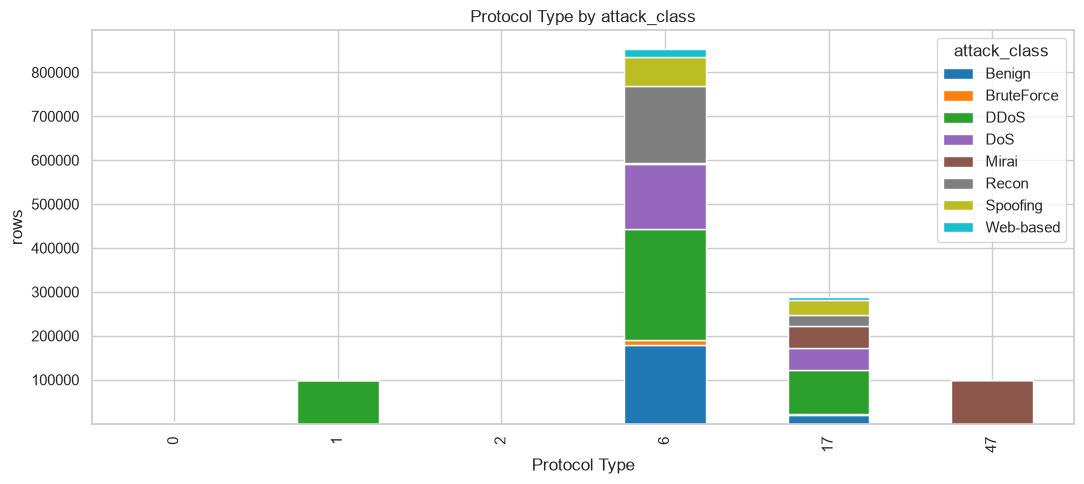

In [18]:
# Categorical-like columns
if "Protocol Type" in df.columns:
    pt = df["Protocol Type"].value_counts().rename("rows").to_frame(); pt["%"] = pt["rows"] / len(df) * 100
    display(pt)
    print("Protocol Type vs attack_class (row %):")
    display((pd.crosstab(df["attack_class"], df["Protocol Type"], normalize="index") * 100).round(2))
    pd.crosstab(df["Protocol Type"], df["attack_class"]).plot.bar(stacked=True, figsize=(11, 5), colormap="tab10")
    plt.title("Protocol Type by attack_class"); plt.ylabel("rows"); plt.tight_layout(); plt.show()

for c in ["Number", "IPv", "LLC"]:
    if c in df.columns and df[c].nunique() < 30:
        print(f"\nValue counts of {c}:"); display(df[c].value_counts().head(10).to_frame("rows"))

## 7. Bivariate / multivariate analysis

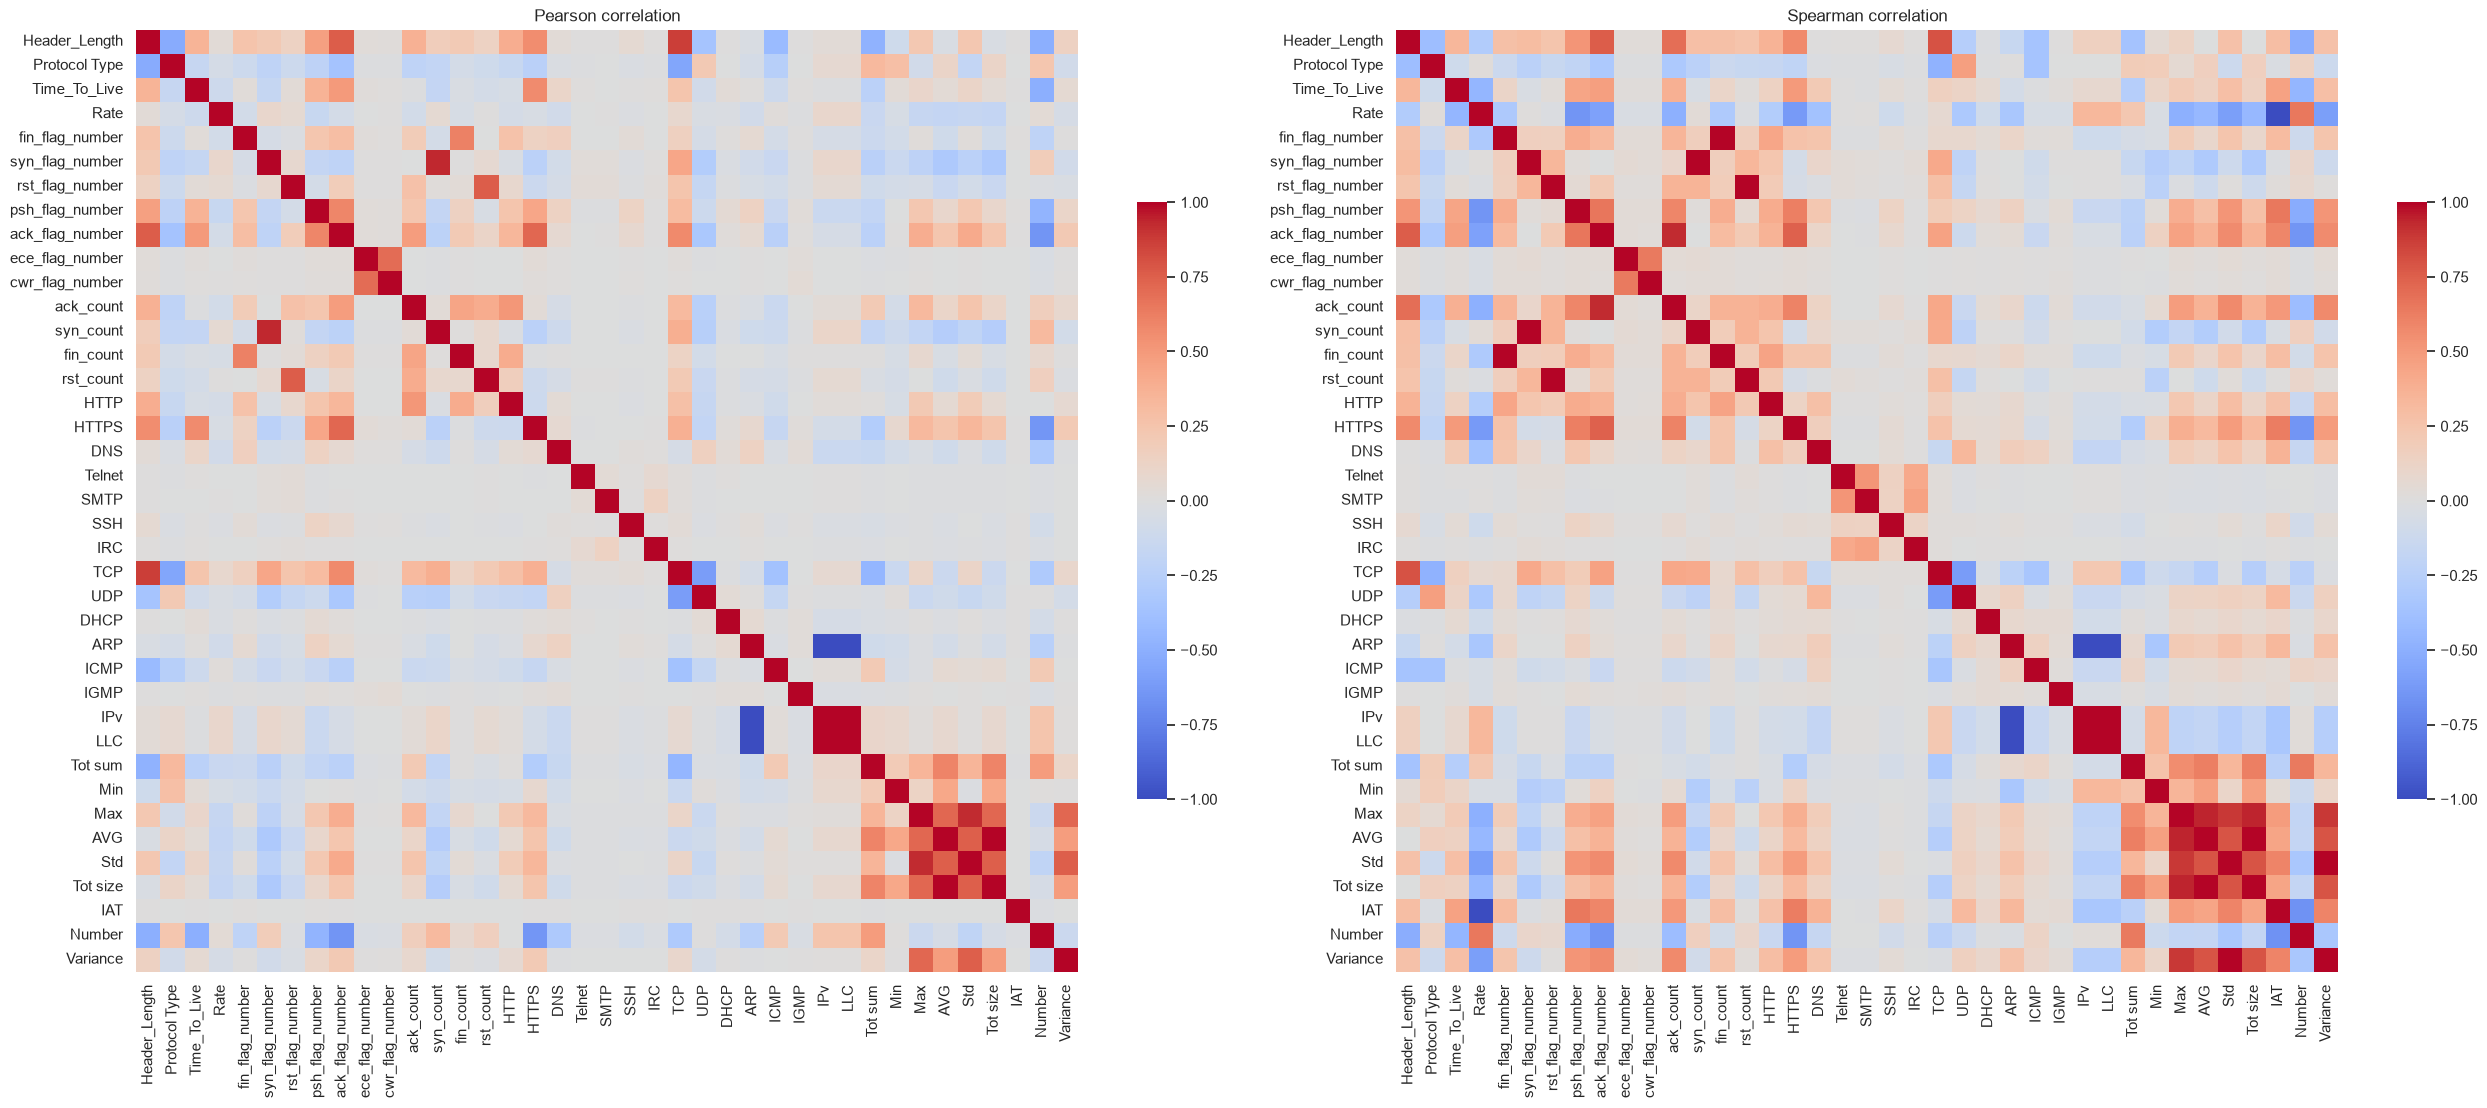

Feature pairs with |Spearman| >= 0.90 : 12


,feature_1,feature_2,r
1322,AVG,Tot size,1
1121,IPv,LLC,1
1004,ARP,LLC,-1
1003,ARP,IPv,-1
1364,Std,Variance,1
248,rst_flag_number,rst_count,0.997369
153,Rate,IAT,-0.996275
169,fin_flag_number,fin_count,0.995354
207,syn_flag_number,syn_count,0.992365
1283,Max,Tot size,0.937701


[saved] outputs\07_high_correlation_pairs.csv


In [19]:
pearson  = S[varying].corr(method="pearson")
spearman = S[varying].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(26, 11))
sns.heatmap(pearson,  cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0], square=True, cbar_kws={"shrink": .6}); axes[0].set_title("Pearson correlation")
sns.heatmap(spearman, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1], square=True, cbar_kws={"shrink": .6}); axes[1].set_title("Spearman correlation")
plt.tight_layout(); plt.show()

def top_pairs(corr, thr=0.9):
    c = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("r").reset_index()
    c.columns = ["feature_1", "feature_2", "r"]
    return c[c["r"].abs() >= thr].sort_values("r", key=abs, ascending=False)

pairs = top_pairs(spearman, 0.9)
print(f"Feature pairs with |Spearman| >= 0.90 : {len(pairs)}")
display(pairs.head(40))
save_table(pairs.set_index("feature_1"), "07_high_correlation_pairs")

,pearson_with_label,spearman_with_label,abs_spearman
Number,0.50795,0.5077,0.5077
HTTPS,-0.524367,-0.495834,0.495834
ack_flag_number,-0.440112,-0.429577,0.429577
IAT,8.26297e-05,-0.379197,0.379197
Rate,0.099191,0.371916,0.371916
Header_Length,-0.339663,-0.35057,0.35057
psh_flag_number,-0.264092,-0.328545,0.328545
Time_To_Live,-0.341978,-0.307151,0.307151
ack_count,0.0662296,-0.285783,0.285783
Std,-0.26669,-0.283905,0.283905


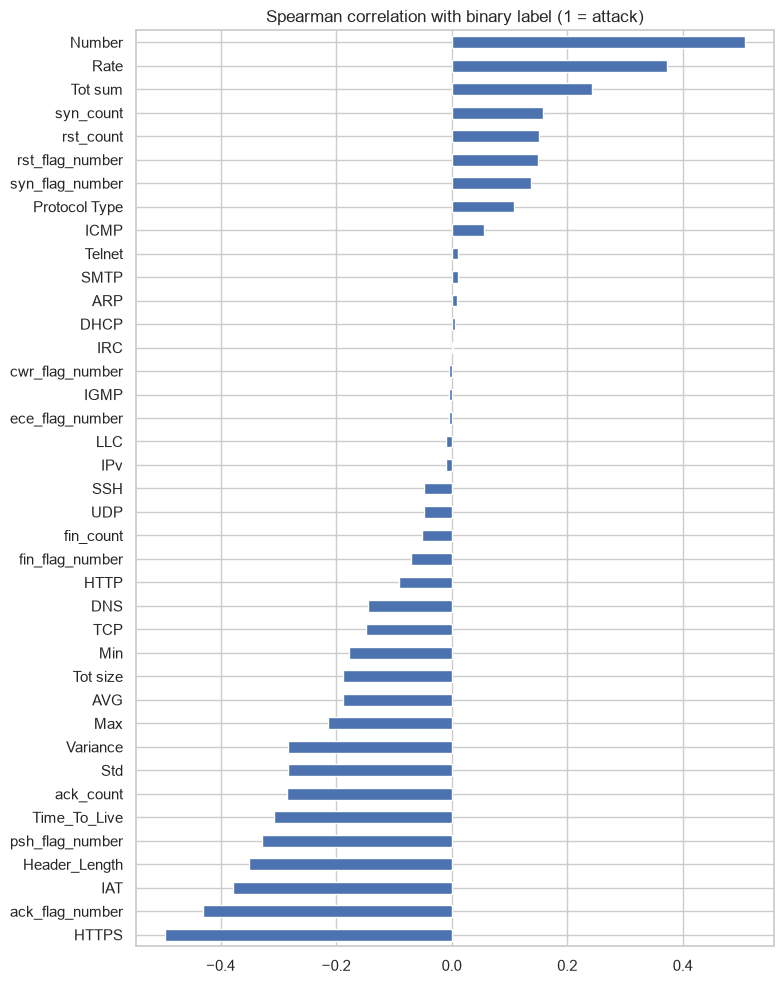

In [20]:
# Correlation of each feature with the binary target (point-biserial = Pearson with 0/1) and with a rank-based measure
tgt_corr = pd.DataFrame({
    "pearson_with_label":  S[varying].corrwith(S["label"], method="pearson"),
    "spearman_with_label": S[varying].corrwith(S["label"], method="spearman"),
})
tgt_corr["abs_spearman"] = tgt_corr["spearman_with_label"].abs()
tgt_corr = tgt_corr.sort_values("abs_spearman", ascending=False)
display(tgt_corr)
tgt_corr["spearman_with_label"].sort_values().plot.barh(figsize=(8, 10), title="Spearman correlation with binary label (1 = attack)")
plt.tight_layout(); plt.show()

Median of each feature by attack_class


attack_class,Benign,BruteForce,DDoS,DoS,Mirai,Recon,Spoofing,Web-based
Header_Length,28.4,24.8,10.08,20,0.32,23.2,22.4,22.4
Protocol Type,6,6,6,6,47,6,6,6
Time_To_Live,93.5,83.1,64,64,64,84.4,82.4,92.4
Rate,161.027,106.396,"9,497.76","18,386.4","4,664.38",149.211,491.718,72.9655
fin_flag_number,0,0,0,0,0,0,0,0
syn_flag_number,0,0,0,0.01,0,0.1,0,0
rst_flag_number,0,0,0,0,0,0,0,0
psh_flag_number,0.1,0.2,0,0,0,0.1,0.1,0.2
ack_flag_number,0.9,0.8,0,0,0,0.6,0.7,0.7
ece_flag_number,0,0,0,0,0,0,0,0


Mean of each feature by attack_class


attack_class,Benign,BruteForce,DDoS,DoS,Mirai,Recon,Spoofing,Web-based
Header_Length,26.7015,23.8838,12.9495,19.9415,3.11503,23.2728,22.7067,22.1132
Protocol Type,7.11142,7.63296,7.34237,8.75066,36.6702,7.26214,9.75698,8.40938
Time_To_Live,108.483,93.1201,65.6245,64.9829,64.8581,94.9563,99.0905,98.9483
Rate,"3,971.58","1,732.28","19,389.5","24,765.6","5,570.12","17,154.1","27,265.7","4,470.84"
fin_flag_number,0.0226932,0.0266075,0.00755034,0.00520604,0.000527351,0.0331574,0.00669907,0.0250493
syn_flag_number,0.0255173,0.0462492,0.245553,0.280662,0.00247753,0.185311,0.0116765,0.0326741
rst_flag_number,0.00192462,0.0102572,0.0194971,0.10889,0.000406087,0.116949,0.00316703,0.00242065
psh_flag_number,0.172916,0.251944,0.0256965,0.0442298,0.00304933,0.15464,0.160858,0.205797
ack_flag_number,0.769526,0.689696,0.150356,0.218883,0.0129867,0.591578,0.599531,0.628518
ece_flag_number,0.00032652,0.000788426,3.91559e-05,1.27505e-05,6.66707e-07,0.000244244,0.000803008,0.000451104


[saved] outputs\07_median_by_attack_class.csv
[saved] outputs\07_mean_by_attack_class.csv


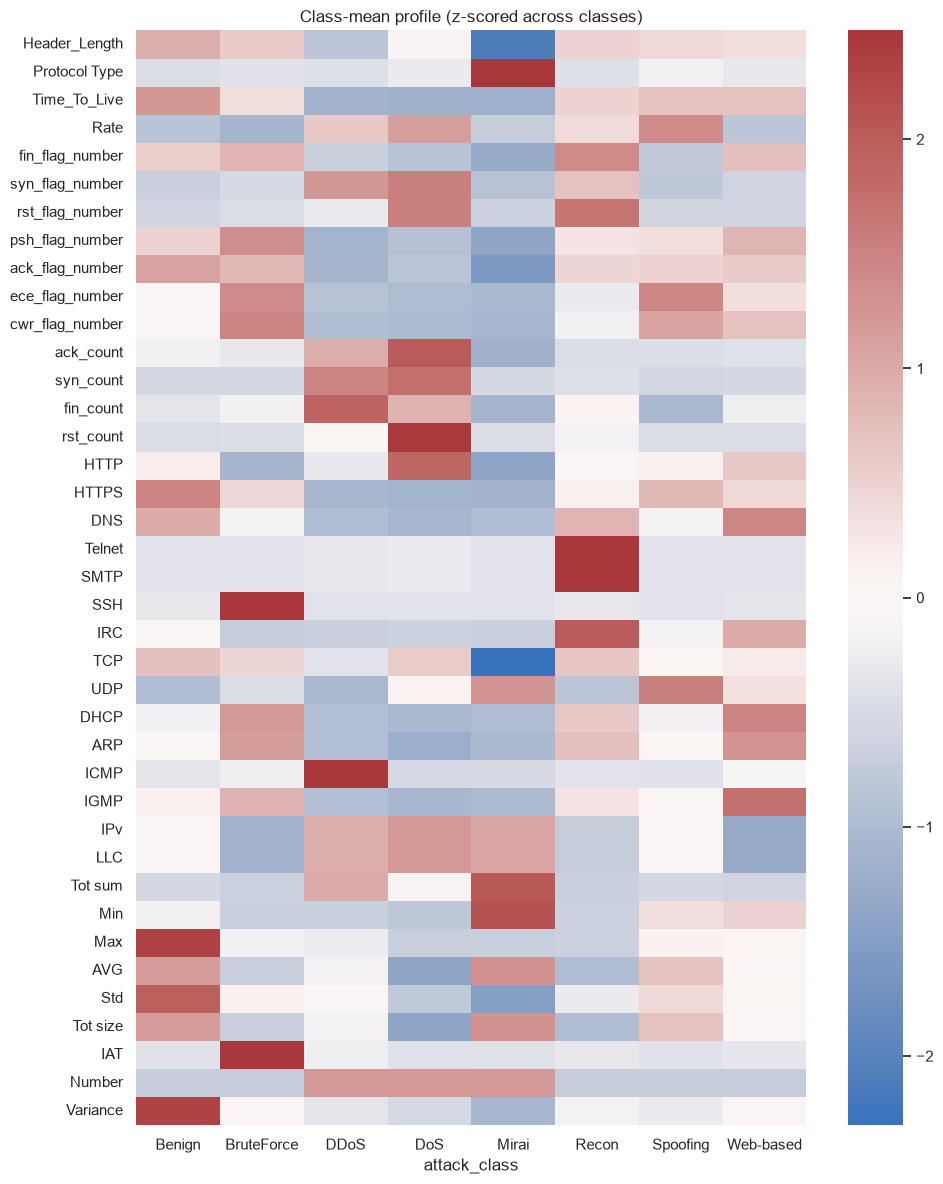

In [21]:
# Per-class profile: median and mean of every feature by attack_class + standardised heat-map
by_cls_median = df.groupby("attack_class")[FEATURES].median().T
by_cls_mean   = df.groupby("attack_class")[FEATURES].mean().T
print("Median of each feature by attack_class"); display(by_cls_median)
print("Mean of each feature by attack_class");   display(by_cls_mean)
save_table(by_cls_median, "07_median_by_attack_class"); save_table(by_cls_mean, "07_mean_by_attack_class")

z = (by_cls_mean - by_cls_mean.mean(axis=1).values[:, None]) / by_cls_mean.std(axis=1).replace(0, np.nan).values[:, None]
plt.figure(figsize=(10, 12)); sns.heatmap(z.fillna(0), cmap="vlag", center=0, annot=False)
plt.title("Class-mean profile (z-scored across classes)"); plt.tight_layout(); plt.show()

In [22]:
pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
# Multicollinearity: Variance Inflation Factor
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

V = slog(S[varying].sample(min(20_000, len(S)), random_state=SEED))
V = V.loc[:, V.std() > 0]
Vc = add_constant(V)
vif = pd.Series([variance_inflation_factor(Vc.values, i) for i in range(1, Vc.shape[1])], index=V.columns, name="VIF").sort_values(ascending=False)
display(vif.to_frame())
print("Features with VIF > 10 (strong multicollinearity):", vif.index[vif > 10].tolist())
report["vif_gt_10"] = vif.index[vif > 10].tolist()

C:\Users\DELL\AppData\Roaming\Python\Python313\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\DELL\AppData\Roaming\Python\Python313\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\DELL\AppData\Roaming\Python\Python313\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\DELL\AppData\Roaming\Python\Python313\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(

,VIF
IPv,1.0008e+15
LLC,1.0008e+15
AVG,2.68435e+08
Tot size,1.55826e+06
Tot sum,"219,302"
Number,"114,121"
Variance,"2,508.73"
Std,"2,447.18"
TCP,101.504
Header_Length,61.7754


Features with VIF > 10 (strong multicollinearity): ['IPv', 'LLC', 'AVG', 'Tot size', 'Tot sum', 'Number', 'Variance', 'Std', 'TCP', 'Header_Length', 'ARP', 'UDP', 'ack_flag_number', 'syn_count', 'syn_flag_number', 'Max', 'ICMP', 'Protocol Type', 'ack_count']


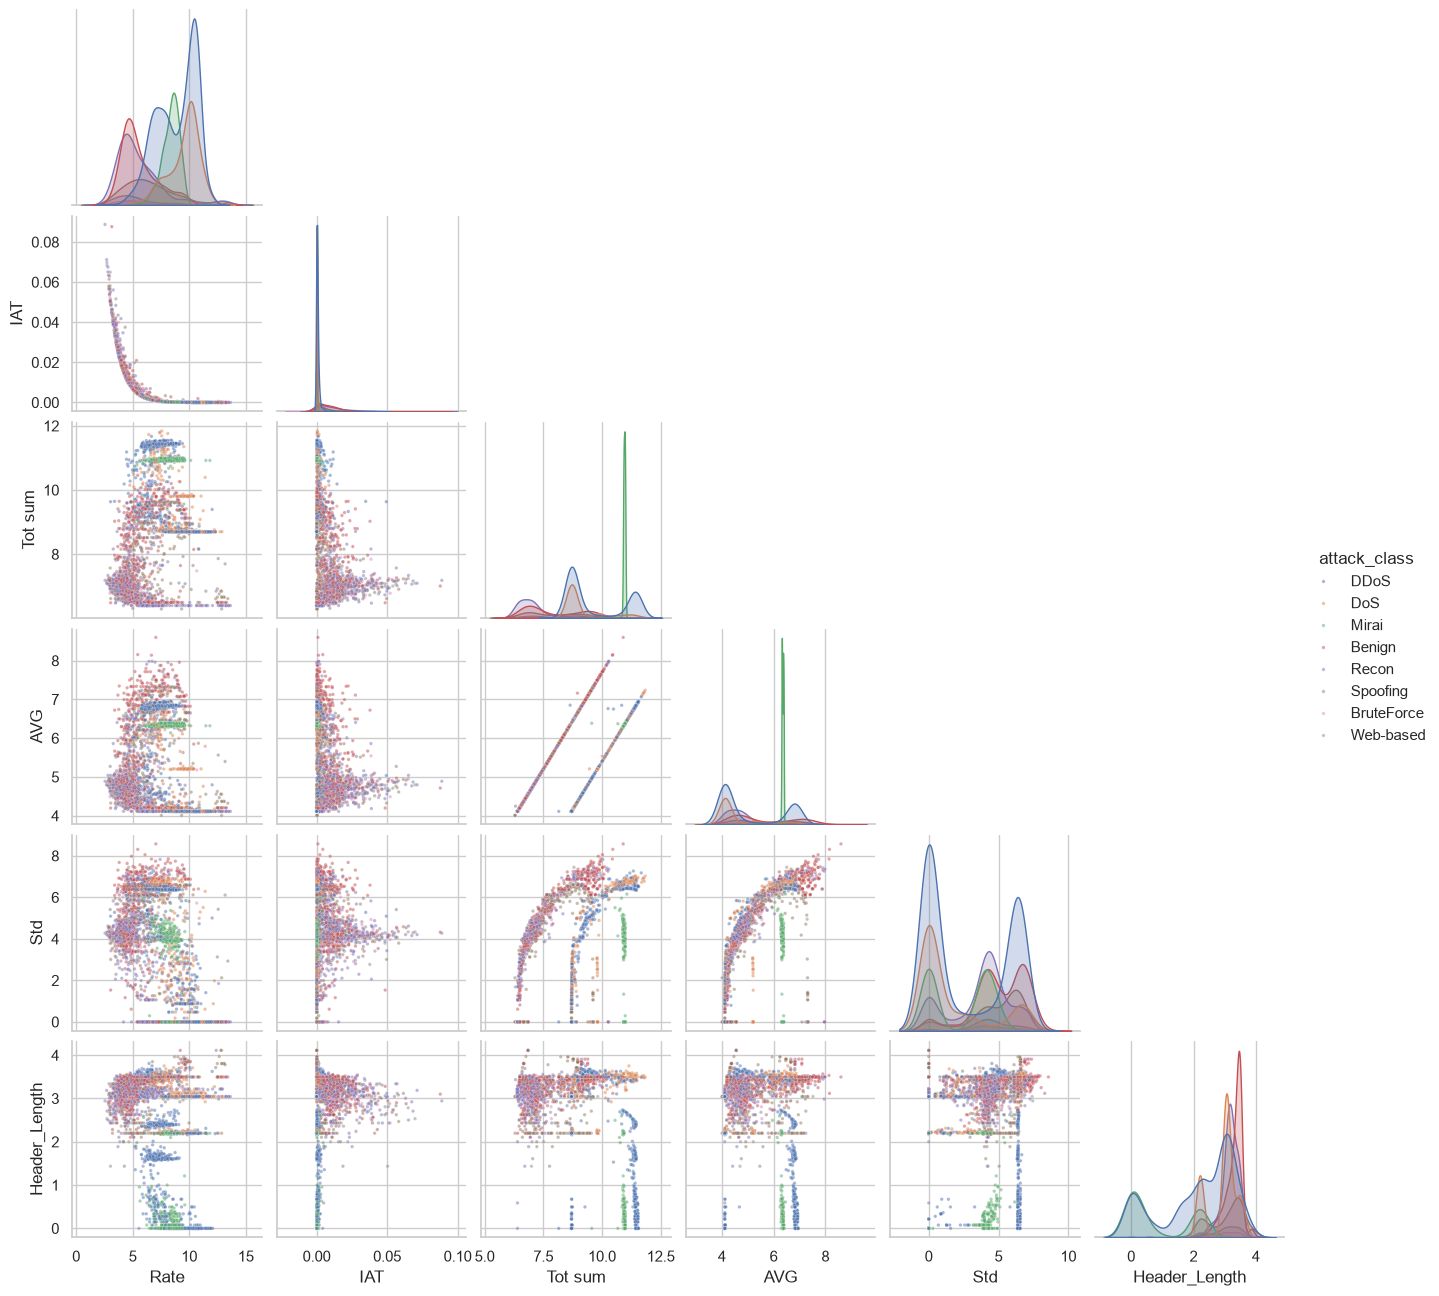

In [24]:
# Pair-plot of the most informative / time-related features
cols_pp = [c for c in ["Rate", "IAT", "Tot sum", "AVG", "Std", "Header_Length"] if c in df.columns]
P = S.sample(min(4000, len(S)), random_state=SEED).copy()
P[cols_pp] = slog(P[cols_pp])
sns.pairplot(P, vars=cols_pp, hue="attack_class", corner=True, plot_kws=dict(s=6, alpha=.5), height=2.2)
plt.show()

## 8. Statistical tests

In [25]:
# 8.1 Normality tests (on a 5 000-row sample; with ~1 M rows every test would reject)
sm = S[varying].sample(min(5000, len(S)), random_state=SEED)
norm_rows = []
for c in varying:
    x = sm[c].values
    k2, p_k2 = stats.normaltest(x)
    w, p_sw  = stats.shapiro(x)
    norm_rows.append(dict(feature=c, dagostino_p=p_k2, shapiro_W=w, shapiro_p=p_sw, skew=stats.skew(x), kurtosis=stats.kurtosis(x)))
normality = pd.DataFrame(norm_rows).set_index("feature")
normality["normal_at_5%"] = (normality["dagostino_p"] > 0.05) & (normality["shapiro_p"] > 0.05)
display(normality)
print("Features that pass BOTH normality tests:", normality.index[normality["normal_at_5%"]].tolist() or "none")
print("-> Distributions are non-normal: non-parametric tests (Mann-Whitney, Kruskal) are the right choice.")

,dagostino_p,shapiro_W,shapiro_p,skew,kurtosis,normal_at_5%
feature,,,,,,
Header_Length,2.74202e-39,0.946405,2.70642e-39,0.0481357,-0.617837,False
Protocol Type,0,0.587977,5.0812e-76,2.35795,4.91919,False
Time_To_Live,0,0.614487,1.25581e-74,2.56397,6.80598,False
Rate,0,0.316782,4.80366e-87,8.23646,87.2776,False
fin_flag_number,0,0.322404,7.37639e-87,5.24933,48.2728,False
syn_flag_number,0,0.523667,4.19082e-79,2.04494,2.53114,False
rst_flag_number,0,0.303437,1.75692e-87,4.64819,22.9813,False
psh_flag_number,0,0.634599,1.62776e-73,2.26752,6.19105,False
ack_flag_number,0,0.783224,4.04086e-63,0.49804,-1.4206,False


Features that pass BOTH normality tests: none
-> Distributions are non-normal: non-parametric tests (Mann-Whitney, Kruskal) are the right choice.


In [26]:
# 8.2 Benign vs Attack: Mann-Whitney U (+ rank-biserial effect size), KS test, Cohen's d
ben = df.loc[df["label"] == 0, varying].sample(min(20_000, int((df["label"]==0).sum())), random_state=SEED)
att = df.loc[df["label"] == 1, varying].sample(min(20_000, int((df["label"]==1).sum())), random_state=SEED)
rows = []
for c in varying:
    a, b = ben[c].values, att[c].values
    u, p_u = stats.mannwhitneyu(a, b, alternative="two-sided")
    ks, p_ks = stats.ks_2samp(a, b)
    rbc = 1 - 2 * u / (len(a) * len(b))               # rank-biserial correlation
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
    d = (a.mean() - b.mean()) / sp if sp > 0 else np.nan
    rows.append(dict(feature=c, median_benign=np.median(a), median_attack=np.median(b), mannwhitney_p=p_u, rank_biserial=rbc, KS_stat=ks, KS_p=p_ks, cohens_d=d))
mw = pd.DataFrame(rows).set_index("feature").sort_values("KS_stat", ascending=False)
display(mw)
save_table(mw, "08_benign_vs_attack_tests")
print("Most discriminative features (by KS statistic):", mw.index[:10].tolist())

,median_benign,median_attack,mannwhitney_p,rank_biserial,KS_stat,KS_p,cohens_d
feature,,,,,,,
Number,10,100,0,0.697601,0.69765,0,-2.14384
HTTPS,0.7,0,0,-0.734088,0.68805,0,1.62996
ack_flag_number,0.9,0.01,0,-0.687735,0.57045,0,1.57905
Time_To_Live,93.5,64,0,-0.497623,0.5333,0,0.863607
IAT,0.0070179,0.000266654,0,-0.601121,0.532,0,0.237247
Header_Length,28.4,19.88,0,-0.578357,0.52455,0,1.17962
ack_count,9,1,0,-0.456903,0.52315,0,-0.23048
Rate,160.811,"3,870.27",0,0.589515,0.51585,0,-0.347039
psh_flag_number,0.1,0,0,-0.462251,0.5034,0,0.724721


[saved] outputs\08_benign_vs_attack_tests.csv
Most discriminative features (by KS statistic): ['Number', 'HTTPS', 'ack_flag_number', 'Time_To_Live', 'IAT', 'Header_Length', 'ack_count', 'Rate', 'psh_flag_number', 'Tot sum']


In [27]:
# 8.3 Kruskal-Wallis across the 8 attack classes (+ epsilon-squared effect size)
cls_groups = {k: v for k, v in S.groupby("attack_class")}
kw_rows = []
for c in varying:
    groups = [g[c].values for g in cls_groups.values() if len(g) > 1]
    H, p = stats.kruskal(*groups)
    eps2 = H / (len(S) - 1) if len(S) > 1 else np.nan
    kw_rows.append(dict(feature=c, H=H, p_value=p, epsilon_squared=eps2))
kw = pd.DataFrame(kw_rows).set_index("feature").sort_values("epsilon_squared", ascending=False)
display(kw)

# 8.4 Chi-square + Cramér's V : categorical-like columns vs targets
def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2, p, dof, _ = stats.chi2_contingency(ct)
    n_ = ct.values.sum(); r, k = ct.shape
    return chi2, p, dof, np.sqrt((chi2 / n_) / max(min(r - 1, k - 1), 1))

chi_rows = []
for c in [c for c in ["Protocol Type", "Number", "IPv", "LLC", "HTTP", "HTTPS", "DNS", "TCP", "UDP", "ICMP"] if c in df.columns]:
    col = S[c].round(1) if S[c].nunique() > 30 else S[c]
    for t in ["label", "attack_class"]:
        chi2, p, dof, v = cramers_v(col, S[t])
        chi_rows.append(dict(feature=c, target=t, chi2=chi2, p_value=p, dof=dof, cramers_V=v))
display(pd.DataFrame(chi_rows).sort_values("cramers_V", ascending=False))

,H,p_value,epsilon_squared
feature,,,
Number,"49,720.4",0,0.994427
Tot sum,"24,717.5",0,0.494359
IAT,"23,728.6",0,0.474582
HTTPS,"23,635.2",0,0.472714
ack_flag_number,"23,177.2",0,0.463554
Rate,"22,759.2",0,0.455193
Header_Length,"20,764.5",0,0.415298
Protocol Type,"18,589.3",0,0.371793
psh_flag_number,"14,601.9",0,0.292044


,feature,target,chi2,p_value,dof,cramers_V
10,HTTPS,label,"15,217.8",0,10,0.551684
2,Number,label,"12,943.6",0,68,0.508794
1,Protocol Type,attack_class,"43,669.8",0,28,0.467278
14,TCP,label,"7,282.61",0,10,0.381644
3,Number,attack_class,"50,247.5",0,476,0.378899
16,UDP,label,"5,994.3",0,10,0.346246
11,HTTPS,attack_class,"33,718.1",0,70,0.310383
15,TCP,attack_class,"33,452.6",0,70,0.309158
12,DNS,label,"3,528.58",0,9,0.265653
17,UDP,attack_class,"23,000.7",0,70,0.256352


In [28]:
# 8.5 Drift between splits: KS statistic + Population Stability Index (PSI) train vs validation / test
def psi(a, b, bins=10):
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0
    pa = np.histogram(a, bins=edges)[0] / len(a); pb = np.histogram(b, bins=edges)[0] / len(b)
    pa, pb = np.clip(pa, 1e-6, None), np.clip(pb, 1e-6, None)
    return float(np.sum((pa - pb) * np.log(pa / pb)))

drift_rows = []
tr = df[df["split"] == "train"]
for other in [s for s in df["split"].unique() if s != "train"]:
    ot = df[df["split"] == other]
    for c in varying:
        a = tr[c].sample(min(30_000, len(tr)), random_state=SEED).values; b = ot[c].sample(min(30_000, len(ot)), random_state=SEED).values
        ks, p = stats.ks_2samp(a, b)
        drift_rows.append(dict(split=other, feature=c, KS=ks, KS_p=p, PSI=psi(a, b)))
drift = pd.DataFrame(drift_rows)
display(drift.sort_values("PSI", ascending=False).head(15))
print("Max PSI:", round(drift["PSI"].max(), 5), "(< 0.1 = no meaningful drift) ->", "random split confirmed: splits are statistically alike" if drift["PSI"].max() < 0.1 else "some drift detected")
report["max_psi_between_splits"] = round(float(drift["PSI"].max()), 5)

,split,feature,KS,KS_p,PSI
75,validation,IAT,0.0065,0.548312,0.000816911
2,test,Time_To_Live,0.0042,0.952972,0.000762068
69,validation,Tot sum,0.00576667,0.698507,0.000702366
72,validation,AVG,0.0071,0.434098,0.000693173
74,validation,Tot size,0.0071,0.434098,0.000693173
42,validation,Rate,0.0063,0.588718,0.000670152
33,test,AVG,0.0051,0.828139,0.000632844
35,test,Tot size,0.0051,0.828139,0.000632844
23,test,UDP,0.0069,0.470757,0.000619695
62,validation,UDP,0.0073,0.399083,0.000614951


Max PSI: 0.00082 (< 0.1 = no meaningful drift) -> random split confirmed: splits are statistically alike


## 9. Outlier analysis

In [29]:
def outlier_table(d):
    rows = []
    for c in d.columns:
        s = d[c].replace([np.inf, -np.inf], np.nan).dropna()
        q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        med = s.median(); mad = (s - med).abs().median()
        z = np.abs((s - s.mean()) / s.std()) if s.std() > 0 else pd.Series(0, index=s.index)
        mz = np.abs(0.6745 * (s - med) / mad) if mad > 0 else pd.Series(np.nan, index=s.index)
        rows.append(dict(
            feature=c,
            IQR_1_5_pct = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100 if iqr > 0 else np.nan,
            IQR_3_0_pct = ((s < q1 - 3.0 * iqr) | (s > q3 + 3.0 * iqr)).mean() * 100 if iqr > 0 else np.nan,
            z_gt_3_pct  = (z > 3).mean() * 100,
            modz_gt_3_5_pct = (mz > 3.5).mean() * 100 if mad > 0 else np.nan,
            IQR_equals_0 = iqr == 0))
    return pd.DataFrame(rows).set_index("feature")

outl = outlier_table(df[varying])
display(outl.sort_values("IQR_1_5_pct", ascending=False))
print("Note: NaN = IQR or MAD is 0 (feature is zero-dominated) so IQR/modified-z rules are not meaningful there.")
save_table(outl, "09_outliers_per_feature")

,IQR_1_5_pct,IQR_3_0_pct,z_gt_3_pct,modz_gt_3_5_pct,IQR_equals_0
feature,,,,,
syn_count,19.0175,17.3541,0,NaN,False
syn_flag_number,17.1786,14.6721,0,NaN,False
Min,15.7977,13.0869,1.31482,NaN,False
IAT,15.4354,8.79377,0.00104298,28.8982,False
Time_To_Live,14.6908,8.92779,3.03185,33.6707,False
UDP,14.0945,0,0,40.6099,False
psh_flag_number,13.1613,3.39541,1.57661,NaN,False
HTTPS,12.7818,0,0,NaN,False
ack_count,12.427,11.2686,4.34183,12.6864,False


Note: NaN = IQR or MAD is 0 (feature is zero-dominated) so IQR/modified-z rules are not meaningful there.
[saved] outputs\09_outliers_per_feature.csv


IsolationForest (unsupervised, fit on ALL data)   ROC-AUC vs attack label: 0.4317
IsolationForest (fit on BENIGN only)              ROC-AUC vs attack label: 0.9020
LOF (10k sample)                                  ROC-AUC vs attack label: 0.5518


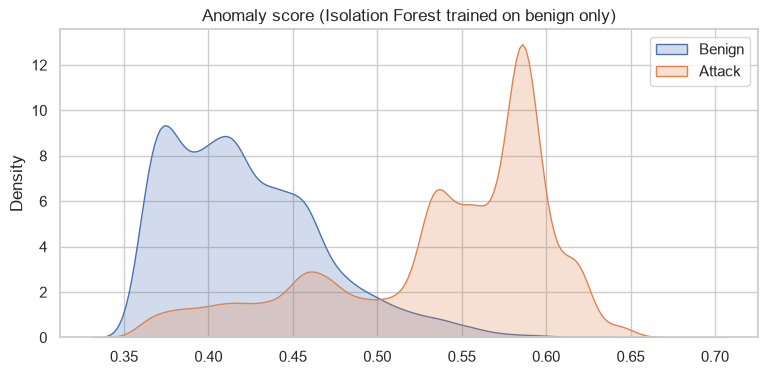

In [30]:
# Multivariate anomaly detection: Isolation Forest + Local Outlier Factor
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

Xs_ = StandardScaler().fit_transform(slog(S[varying].values))
y_s = S["label"].values

iso = IsolationForest(n_estimators=200, contamination="auto", random_state=SEED, n_jobs=-1).fit(Xs_)
iso_score = -iso.score_samples(Xs_)
print(f"IsolationForest (unsupervised, fit on ALL data)   ROC-AUC vs attack label: {roc_auc_score(y_s, iso_score):.4f}")

# novelty-detection setting: learn ONLY benign traffic, then score everything
iso_b = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(Xs_[y_s == 0])
iso_b_score = -iso_b.score_samples(Xs_)
print(f"IsolationForest (fit on BENIGN only)              ROC-AUC vs attack label: {roc_auc_score(y_s, iso_b_score):.4f}")

sub = rng.choice(len(Xs_), size=min(10_000, len(Xs_)), replace=False)
lof = LocalOutlierFactor(n_neighbors=35, contamination="auto").fit(Xs_[sub])
lof_score = -lof.negative_outlier_factor_
print(f"LOF (10k sample)                                  ROC-AUC vs attack label: {roc_auc_score(y_s[sub], lof_score):.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(iso_b_score[y_s == 0], label="Benign", ax=ax, fill=True); sns.kdeplot(iso_b_score[y_s == 1], label="Attack", ax=ax, fill=True)
ax.set_title("Anomaly score (Isolation Forest trained on benign only)"); ax.legend(); plt.show()
report["isoforest_benign_only_auc"] = round(float(roc_auc_score(y_s, iso_b_score)), 4)

## 10. Temporal / time analysis
There is **no timestamp** in CIC-IoT-2023 flows, so we analyse what *does* describe time:

| Feature | Meaning |
|---|---|
| `IAT` | Inter-arrival time between packets of the flow window |
| `Rate` | Packet rate of the flow window (packets / second) |
| `Number` | Number of packets in the window (10 or 100) |
| `duration_proxy = IAT × Number` | Approximate duration of the window (same unit as `IAT`) |
| `throughput_proxy = Tot sum / duration_proxy` | Approximate bytes per time unit |

Then we **test whether row order contains temporal structure** (it should not, because the data was shuffled), and we draw an *illustrative* reconstructed timeline per class.

In [31]:
df["duration_proxy"]   = df["IAT"] * df["Number"]
df["throughput_proxy"] = df["Tot sum"] / df["duration_proxy"].replace(0, np.nan)
T_COLS = ["IAT", "Rate", "Number", "duration_proxy", "throughput_proxy"]

t_desc = describe_full(df[T_COLS])
display(t_desc)
save_table(t_desc, "10_time_features_descriptive")
report["IAT_min"] = float(df["IAT"].min()); report["IAT_median"] = float(df["IAT"].median()); report["IAT_max"] = float(df["IAT"].max())
report["Rate_min"] = float(df["Rate"].min()); report["Rate_median"] = float(df["Rate"].median()); report["Rate_max"] = float(df["Rate"].max())

,count,missing,n_unique,mean,std,min,p01,p05,p25,median,p75,p95,p99,max,range,IQR,MAD,CV,skew,kurtosis,mode,zeros_%,sum
IAT,1342314,0,499330,0.0687361,45.9914,-0.00646646,4.72069e-06,1.90989e-05,6.66213e-05,0.000438352,0.00404749,0.0235381,0.0485094,"46,665.2","46,665.2",0.00398087,0.000414121,669.1,896.873,"852,603",3.09944e-06,0,"92,265.5"
Rate,1342314,0,485529,"16,151.4","50,031.3",2.14292e-05,22.6148,47.3042,277.739,"2,392.28","15,523.5","53,676.8","277,768",6.29146e+06,6.29146e+06,"15,245.8","2,320.87",3.09765,13.3073,533.865,"322,639",0,2.16802e+10
Number,1342314,0,99,63.6806,44.1261,2,10,10,10,100,100,100,100,100,98,90,0,0.692928,-0.393281,-1.84418,100,0,8.54794e+07
duration_proxy,1342314,0,499561,4.0019,"4,034.94",-0.646646,5.19753e-05,0.00135207,0.00481391,0.0232091,0.088254,0.295657,0.633659,4.66652e+06,4.66652e+06,0.0834401,0.0208082,"1,008.26","1,152.61",1.33282e+06,3.09944e-05,0,5.3718e+06
throughput_proxy,1342314,0,1010900,1.91943e+06,6.69697e+06,"-9,278.65","2,313.06","4,823.58","53,742.5","875,204",2.23537e+06,6.30982e+06,1.77597e+07,1.77734e+09,1.77735e+09,2.18163e+06,"857,854",3.48905,78.4144,"12,565.1",1.93583e+07,0,2.57647e+12


[saved] outputs\10_time_features_descriptive.csv


In [32]:
def grp_stats(col, by):
    g = df.groupby(by)[col]
    return pd.DataFrame({"count": g.count(), "min": g.min(), "p25": g.quantile(.25), "median": g.median(),
                         "mean": g.mean(), "p75": g.quantile(.75), "p95": g.quantile(.95), "max": g.max(), "std": g.std()})

for col in ["IAT", "Rate", "duration_proxy", "throughput_proxy"]:
    print(f"\n===== {col} by attack_class ====="); display(grp_stats(col, "attack_class"))
print("\n===== IAT by Label (34 types) ====="); display(grp_stats("IAT", "Label").sort_values("median"))
print("\n===== Rate by Label (34 types) =====");  display(grp_stats("Rate", "Label").sort_values("median", ascending=False))


===== IAT by attack_class =====


,count,min,p25,median,mean,p75,p95,max,std
attack_class,,,,,,,,,
Benign,199988,9.05991e-07,0.00215135,0.0070632,0.00920709,0.0128091,0.026969,0.115498,0.00931836
BruteForce,13064,1.38283e-06,0.00463236,0.0104282,1.94917,0.0213441,0.0484462,"24,768",216.725
DDoS,452195,2.38419e-07,3.12805e-05,0.000106409,0.105889,0.00062438,0.00258338,"46,665.2",69.4008
DoS,199992,-0.00646646,3.241e-05,5.5095e-05,0.00727787,0.00018916,0.00123781,632.41,2.0008
Mirai,149991,6.35783e-07,0.000138631,0.000216851,0.000654623,0.00037739,0.00112884,10.8162,0.0367543
Recon,202257,3.8147e-07,0.0015512,0.0076551,0.0627223,0.0165068,0.041767,"6,689.96",15.1956
Spoofing,99999,4.05312e-07,0.000405848,0.00231879,0.0161379,0.00816923,0.0338463,312.052,1.09606
Web-based,24828,8.10623e-07,0.00513393,0.0155244,0.0493086,0.0316774,0.0627373,192.008,1.50471



===== Rate by attack_class =====


,count,min,p25,median,mean,p75,p95,max,std
attack_class,,,,,,,,,
Benign,199988,9.42655,85.204,161.027,"3,971.58",557.737,"9,871.27",1.271e+06,"33,625.5"
BruteForce,13064,4.03747e-05,52.4119,106.396,"1,732.28",249.955,"1,203.69","762,601","24,243.2"
DDoS,452195,2.14292e-05,"1,618.87","9,497.76","19,389.5","32,363.5","56,405.4",6.29146e+06,"29,734.8"
DoS,199992,0.00158125,"5,362.12","18,386.4","24,765.6","31,230.9","72,465.5",5.24288e+06,"34,705.9"
Mirai,149991,0.0924539,"2,674.7","4,664.38","5,570.12","7,321.69","13,060.1",3.14573e+06,"11,774.3"
Recon,202257,0.00120766,66.7579,149.211,"17,154.1",737.201,"38,304.1",2.62144e+06,"86,341.7"
Spoofing,99999,0.015151,136.689,491.718,"27,265.7","3,053.96","287,281",2.46724e+06,"91,592.5"
Web-based,24828,0.0052082,35.1155,72.9655,"4,470.84",230.142,"7,813.53",1.23362e+06,"36,617"



===== duration_proxy by attack_class =====


,count,min,p25,median,mean,p75,p95,max,std
attack_class,,,,,,,,,
Benign,199988,9.05991e-06,0.0215097,0.0706255,0.0920626,0.128077,0.269686,1.15498,0.0931819
BruteForce,13064,1.38283e-05,0.0463236,0.104275,19.4917,0.213441,0.484462,"247,680","2,167.25"
DDoS,452195,9.53674e-07,0.00312495,0.0105779,10.5887,0.0622339,0.257787,4.66652e+06,"6,940.08"
DoS,199992,-0.646646,0.0032382,0.00550485,0.727729,0.018882,0.123412,"63,241",200.08
Mirai,149991,1.90735e-06,0.0138241,0.0216389,0.0653611,0.0376666,0.112607,"1,081.62",3.67542
Recon,202257,3.8147e-06,0.0155101,0.0765421,0.627215,0.165056,0.41763,"66,899.6",151.956
Spoofing,99999,4.05312e-06,0.00405645,0.0231819,0.161374,0.0816876,0.338463,"3,120.52",10.9606
Web-based,24828,8.10623e-06,0.0512498,0.155238,0.49305,0.316726,0.627373,"1,920.08",15.0471


... (2 outputs left out)


===== IAT by Label (34 types) =====


,count,min,p25,median,mean,p75,p95,max,std
Label,,,,,,,,,
DoS-TCP_Flood,49999,5.6982e-07,1.64008e-05,2.50101e-05,0.000113232,4.75454e-05,0.000154934,3.05477,0.013686
DDoS-ICMP_Flood,50000,6.79493e-07,2.07877e-05,2.98548e-05,5.07578e-05,5.11926e-05,0.00012713,0.0227741,0.00023814
DDoS-SynonymousIP_Flood,50000,1.02997e-06,2.27404e-05,3.01003e-05,0.00020811,4.95219e-05,0.00012031,7.79872,0.034878
DDoS-TCP_Flood,49999,2.38419e-07,2.29692e-05,3.10493e-05,0.001021,5.2439e-05,0.000148744,47.4122,0.212036
DDoS-UDP_Flood,49998,1.95026e-06,2.31695e-05,3.19147e-05,6.92641e-05,5.60802e-05,0.000132593,0.0583985,0.000738056
DoS-SYN_Flood,49997,1.90735e-07,3.33905e-05,4.58288e-05,7.71165e-05,8.12602e-05,0.000232491,0.00681499,0.000106396
DoS-UDP_Flood,49998,-0.00646646,3.64995e-05,5.09202e-05,0.012652,9.36103e-05,0.000284708,627.605,2.80679
DDoS-SYN_Flood,49999,3.42846e-06,3.39592e-05,5.46098e-05,9.19235e-05,0.000100489,0.000243171,0.0226966,0.000284501
Mirai-udpplain,49999,1.03315e-06,0.00012293,0.00019191,0.00057151,0.000310855,0.000764223,3.61723,0.0215761



===== Rate by Label (34 types) =====


,count,min,p25,median,mean,p75,p95,max,std
Label,,,,,,,,,
DoS-TCP_Flood,49999,0.327358,"21,289.8","40,485.6","47,688.5","61,653.7","111,610",1.75494e+06,"44,723.4"
DDoS-ICMP_Flood,50000,44.2619,"19,770.5","33,920.8","39,395.7","48,763.9","98,805.7",1.47169e+06,"31,372.4"
DDoS-SynonymousIP_Flood,50000,0.128226,"20,437.1","33,589.4","34,933.6","44,501.9","63,091.2",1.04858e+06,"23,184.5"
DDoS-TCP_Flood,49999,0.0210916,"19,286.8","32,592.3","34,919.6","44,071.7","71,848.6",4.1943e+06,"30,954.1"
DDoS-UDP_Flood,49998,17.1678,"18,033.8","31,741.4","33,545.8","43,690.7","63,694.8","512,751","22,141.5"
DoS-SYN_Flood,49997,148.713,"12,434.6","22,089.2","24,283.6","30,292.5","48,827.8",5.24288e+06,"31,100.6"
DoS-UDP_Flood,49998,0.00159336,"10,785.1","19,882.5","20,247","27,753","36,377.3",3.14573e+06,"19,660.6"
DDoS-SYN_Flood,49999,44.2435,"10,076","18,553.1","22,858.7","29,831.5","48,993.2",6.29146e+06,"34,897.6"
Mirai-udpplain,49999,0.276457,"3,248.44","5,271.48","6,210.79","8,260.41","13,727.1",1.3981e+06,"7,994.92"


In [33]:
# Window size (Number) per class
display((pd.crosstab(df["attack_class"], df["Number"], normalize="index") * 100).round(2).loc[:, lambda d: d.sum() > 0.01].head(20))

Number,3,4,5,7,8,9,10,88,89,100
attack_class,,,,,,,,,,
Benign,0.01,0,0,0.01,0.01,0.01,99.96,0,0,0
BruteForce,0,0.01,0,0,0,0.02,99.98,0,0,0
DDoS,0,0,0,0,0,0,0,0.01,0.01,99.64
DoS,0,0,0,0,0,0,0,0,0,99.82
Mirai,0.01,0.01,0.01,0,0,0,0.01,0.01,0.01,99.43
Recon,0,0,0,0,0,0,99.98,0,0,0
Spoofing,0.01,0,0.01,0.01,0,0.01,99.96,0,0,0
Web-based,0.01,0,0.01,0.01,0.01,0,99.96,0,0,0


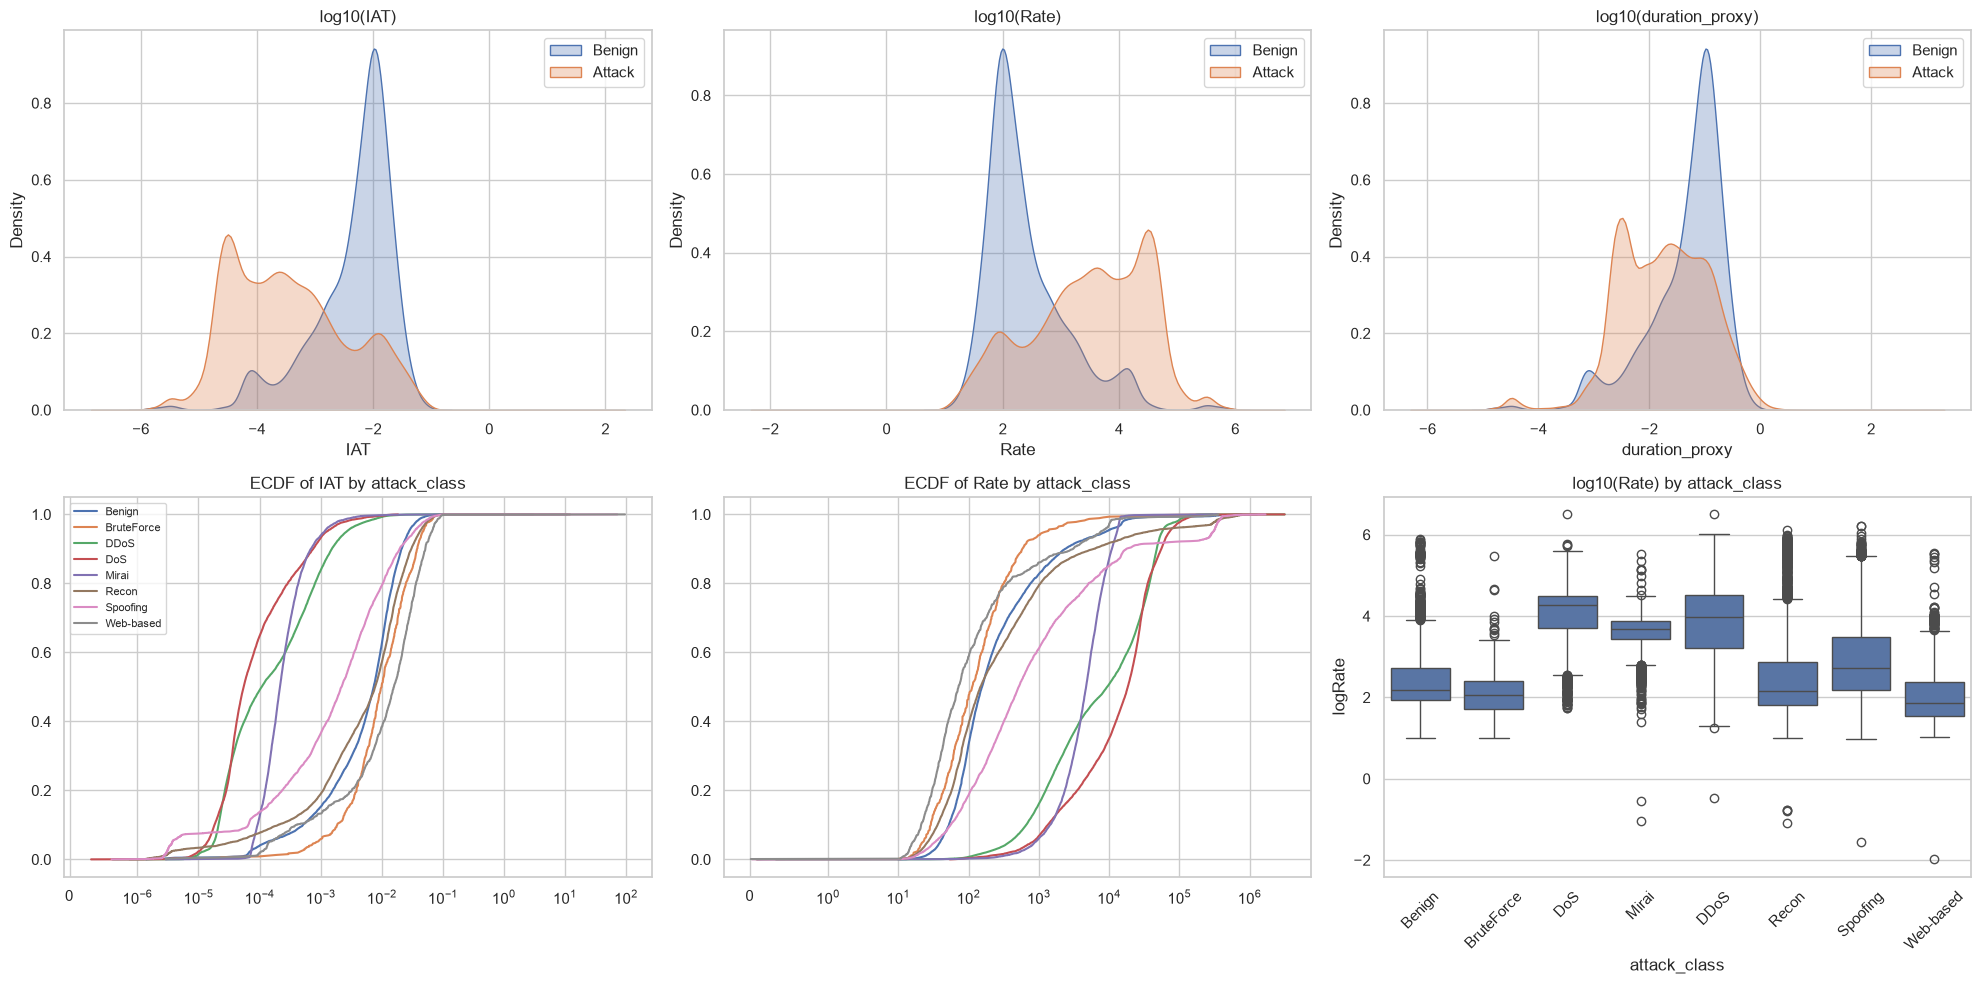

In [34]:
# Distributions on log-scale + ECDF, Benign vs Attack and by class
S = df.sample(min(SAMPLE_N, len(df)), random_state=SEED)
eps = 1e-9
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for lab, name in [(0, "Benign"), (1, "Attack")]:
    sub_ = S[S["label"] == lab]
    sns.kdeplot(np.log10(sub_["IAT"].clip(lower=eps)),  ax=axes[0, 0], label=name, fill=True, alpha=.3)
    sns.kdeplot(np.log10(sub_["Rate"].clip(lower=eps)), ax=axes[0, 1], label=name, fill=True, alpha=.3)
    for ax, col in [(axes[0, 2], "duration_proxy")]:
        sns.kdeplot(np.log10(sub_[col].clip(lower=eps)), ax=ax, label=name, fill=True, alpha=.3)
axes[0, 0].set_title("log10(IAT)"); axes[0, 1].set_title("log10(Rate)"); axes[0, 2].set_title("log10(duration_proxy)")
for ax in axes[0]: ax.legend()

for cls, g in S.groupby("attack_class"):
    x = np.sort(g["IAT"].values); axes[1, 0].plot(x, np.arange(1, len(x) + 1) / len(x), label=cls)
    x = np.sort(g["Rate"].values); axes[1, 1].plot(x, np.arange(1, len(x) + 1) / len(x), label=cls)
axes[1, 0].set_xscale("symlog", linthresh=1e-6); axes[1, 0].set_title("ECDF of IAT by attack_class"); axes[1, 0].legend(fontsize=8)
axes[1, 1].set_xscale("symlog", linthresh=1);    axes[1, 1].set_title("ECDF of Rate by attack_class")
sns.boxplot(data=S.assign(logRate=np.log10(S["Rate"].clip(lower=eps))), x="attack_class", y="logRate", ax=axes[1, 2]); axes[1, 2].tick_params(axis="x", rotation=45); axes[1, 2].set_title("log10(Rate) by attack_class")
plt.tight_layout(); plt.show()

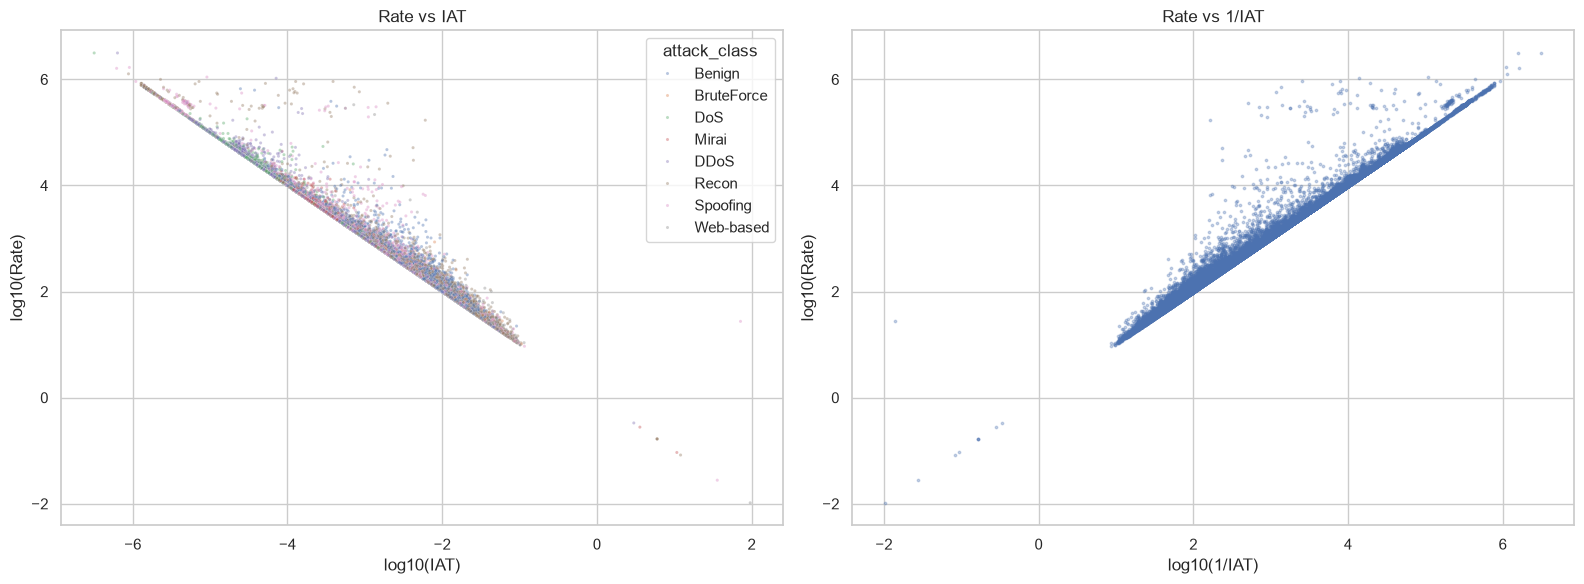

Spearman(Rate, IAT)   = -0.9963
Spearman(Rate, 1/IAT) = 0.9963


In [35]:
# Relationship Rate <-> IAT (are they physically consistent?)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=np.log10(S["IAT"].clip(lower=eps)), y=np.log10(S["Rate"].clip(lower=eps)), hue=S["attack_class"], s=5, alpha=.4, ax=ax[0])
ax[0].set_xlabel("log10(IAT)"); ax[0].set_ylabel("log10(Rate)"); ax[0].set_title("Rate vs IAT")
inv = 1.0 / S["IAT"].replace(0, np.nan)
ax[1].scatter(np.log10(inv.clip(lower=eps)), np.log10(S["Rate"].clip(lower=eps)), s=3, alpha=.3); ax[1].set_xlabel("log10(1/IAT)"); ax[1].set_ylabel("log10(Rate)"); ax[1].set_title("Rate vs 1/IAT")
plt.tight_layout(); plt.show()
print("Spearman(Rate, IAT)   =", round(S[["Rate", "IAT"]].corr(method="spearman").iloc[0, 1], 4))
print("Spearman(Rate, 1/IAT) =", round(pd.concat([S["Rate"], inv], axis=1).corr(method="spearman").iloc[0, 1], 4))

In [36]:
# Burstiness (Goh-Barabasi): B = (sigma - mu) / (sigma + mu)   [-1 regular ... 0 Poisson ... +1 bursty]
# Fano factor of Rate = variance / mean (>1 => over-dispersed / bursty)
def burst(s):
    m, sd = s.mean(), s.std()
    return (sd - m) / (sd + m) if (sd + m) > 0 else np.nan

rows = []
for cls, g in df.groupby("attack_class"):
    rows.append(dict(attack_class=cls, n=len(g),
                     IAT_mean=g["IAT"].mean(), IAT_median=g["IAT"].median(), IAT_cv=g["IAT"].std() / g["IAT"].mean(),
                     burstiness_IAT=burst(g["IAT"]), Rate_fano=g["Rate"].var() / g["Rate"].mean() if g["Rate"].mean() else np.nan,
                     Rate_cv=g["Rate"].std() / g["Rate"].mean() if g["Rate"].mean() else np.nan))
burst_tbl = pd.DataFrame(rows).set_index("attack_class").sort_values("burstiness_IAT", ascending=False)
display(burst_tbl)
save_table(burst_tbl, "10_burstiness_by_class")

,n,IAT_mean,IAT_median,IAT_cv,burstiness_IAT,Rate_fano,Rate_cv
attack_class,,,,,,,
DDoS,452195,0.105889,0.000106409,655.411,0.996953,"45,599.8",1.53355
DoS,199992,0.00727787,5.5095e-05,274.915,0.992751,"48,635.9",1.40137
Recon,202257,0.0627223,0.0076551,242.267,0.991779,"434,584",5.0333
BruteForce,13064,1.94917,0.0104282,111.188,0.982173,"339,283",13.995
Spoofing,99999,0.0161379,0.00231879,67.9187,0.97098,"307,682",3.35925
Mirai,149991,0.000654623,0.000216851,56.1457,0.965002,"24,889",2.11384
Web-based,24828,0.0493086,0.0155244,30.5162,0.936541,"299,901",8.19019
Benign,199988,0.00920709,0.0070632,1.01209,0.00600622,"284,691",8.46653


[saved] outputs\10_burstiness_by_class.csv


,count,mean,std,min,50%,95%,max
attack_class,,,,,,,
Benign,"199,988",1.1973e+06,4.93885e+06,635.985,"31,048.1",1.02011e+07,5.4725e+08
BruteForce,"13,064","239,477",2.11939e+06,0.00368621,"12,423","446,923",1.24976e+08
DDoS,"452,195",1.79502e+06,6.31672e+06,0.00211464,1.47736e+06,4.27279e+06,1.77734e+09
DoS,"199,992",1.88148e+06,2.46431e+06,"-9,278.65",1.43607e+06,5.1067e+06,5.72522e+08
Mirai,"149,991",3.11326e+06,3.983e+06,41.8271,2.63085e+06,7.33749e+06,9.09115e+08
Recon,"202,257",1.4233e+06,7.67359e+06,0.0186399,"18,735.4",9.12806e+06,1.06144e+09
Spoofing,"99,999",3.6261e+06,1.4149e+07,0.237781,"172,419",1.94233e+07,7.63245e+08
Web-based,"24,828",1.14711e+06,6.28749e+06,0.733822,"8,772.87",1.04653e+07,7.81354e+08


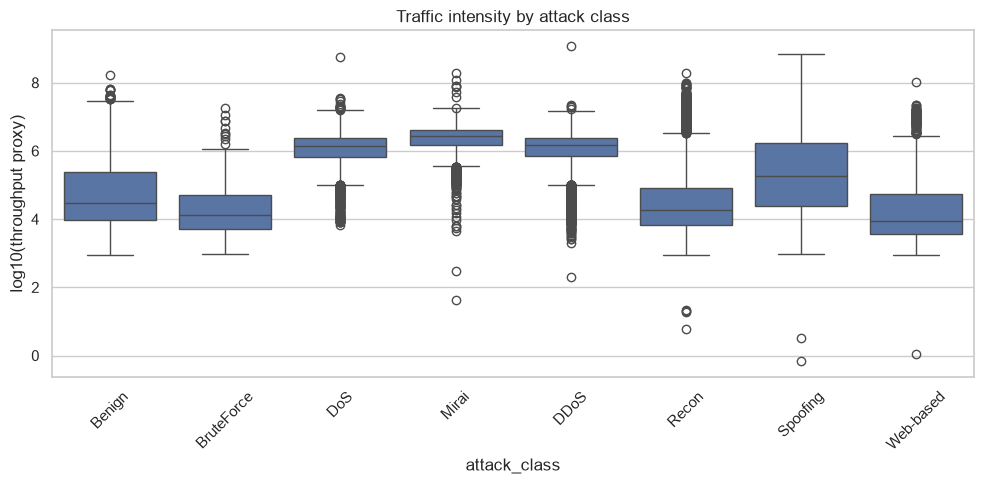

In [37]:
# Throughput proxy (bytes per time unit) and per-class traffic intensity
thr = df.replace([np.inf, -np.inf], np.nan).groupby("attack_class")["throughput_proxy"].describe(percentiles=[.5, .95])
display(thr)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df.sample(min(SAMPLE_N, len(df)), random_state=SEED).assign(l=lambda d: np.log10(d["throughput_proxy"].replace([np.inf, -np.inf], np.nan).clip(lower=eps))),
            x="attack_class", y="l", ax=ax); ax.set_ylabel("log10(throughput proxy)"); ax.tick_params(axis="x", rotation=45)
plt.title("Traffic intensity by attack class"); plt.tight_layout(); plt.show()

### 10.b Does the row order carry time information?
If the dataset kept a temporal order we would see **autocorrelation**, **runs** of the same class and **trends**.
We use the **train split in its stored order** and test: runs test on the label, autocorrelation (ACF) + Ljung-Box on `log Rate` / `log IAT`, ADF stationarity test, periodogram, CUSUM and rolling statistics.

Runs test on label sequence: observed runs=50,741  expected=50,844  z=-0.91  p=0.3646  -> order looks RANDOM (shuffled)
Ljung-Box label        p-values (lag 10/20/40): [0.0302, 0.0947, 0.0494]
Ljung-Box log10(Rate)  p-values (lag 10/20/40): [0.6711, 0.6821, 0.8242]
Ljung-Box log10(IAT)   p-values (lag 10/20/40): [0.6128, 0.5987, 0.7292]


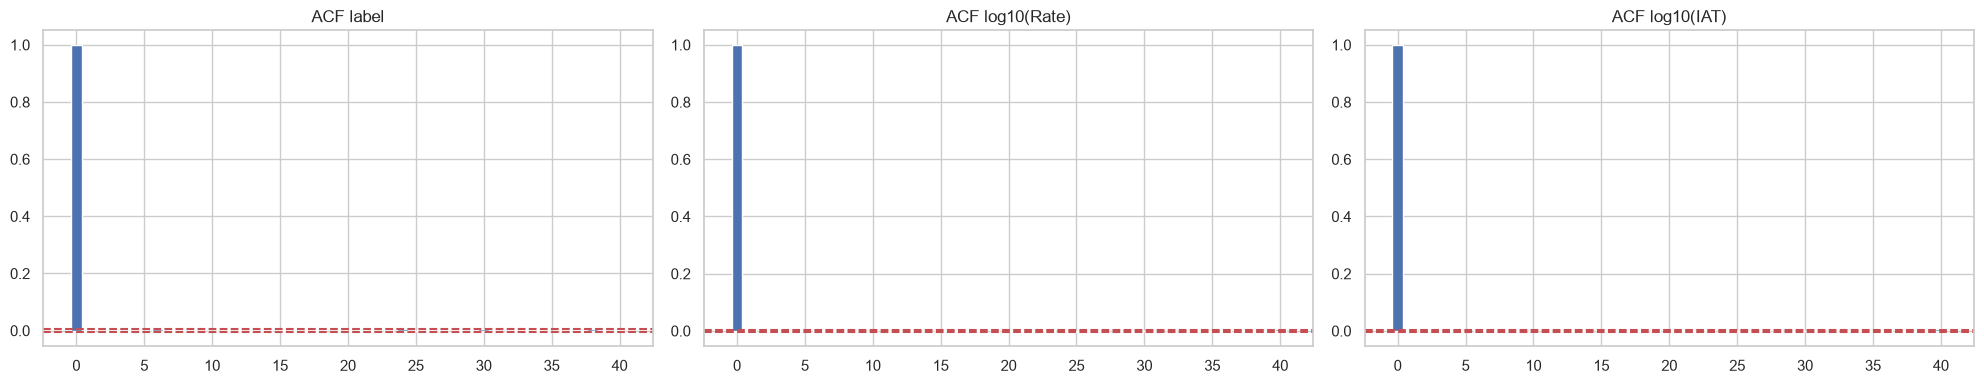

In [38]:
from statsmodels.tsa.stattools import acf, adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

seq = df[df["split"] == "train"].reset_index(drop=True).head(200_000)
lr  = np.log10(seq["Rate"].clip(lower=eps)).values
li  = np.log10(seq["IAT"].clip(lower=eps)).values
yb  = seq["label"].values

# ---- Runs test on binary label ----
def runs_test(b):
    b = np.asarray(b).astype(int); n1 = b.sum(); n0 = len(b) - n1
    runs = 1 + np.sum(b[1:] != b[:-1])
    mu = 2 * n1 * n0 / (n1 + n0) + 1; var = (mu - 1) * (mu - 2) / (n1 + n0 - 1)
    z = (runs - mu) / np.sqrt(var); p = 2 * (1 - stats.norm.cdf(abs(z)))
    return runs, mu, z, p

runs, mu, z, p = runs_test(yb)
print(f"Runs test on label sequence: observed runs={runs:,}  expected={mu:,.0f}  z={z:.2f}  p={p:.4f}  ->",
      "order looks RANDOM (shuffled)" if p > 0.01 else "order shows structure")
report["runs_test_p"] = round(float(p), 5)

# ---- ACF + Ljung-Box ----
nl = 40
fig, axes = plt.subplots(1, 3, figsize=(20, 4))
for ax, (nm, x) in zip(axes, [("label", yb.astype(float)), ("log10(Rate)", lr), ("log10(IAT)", li)]):
    a = acf(x, nlags=nl, fft=True); conf = 1.96 / np.sqrt(len(x))
    ax.bar(range(nl + 1), a); ax.axhline(conf, color="r", ls="--"); ax.axhline(-conf, color="r", ls="--"); ax.set_title(f"ACF {nm}")
    lb = acorr_ljungbox(x[:50_000], lags=[10, 20, 40], return_df=True)
    print(f"Ljung-Box {nm:12s} p-values (lag 10/20/40):", lb["lb_pvalue"].round(4).tolist())
plt.tight_layout(); plt.show()

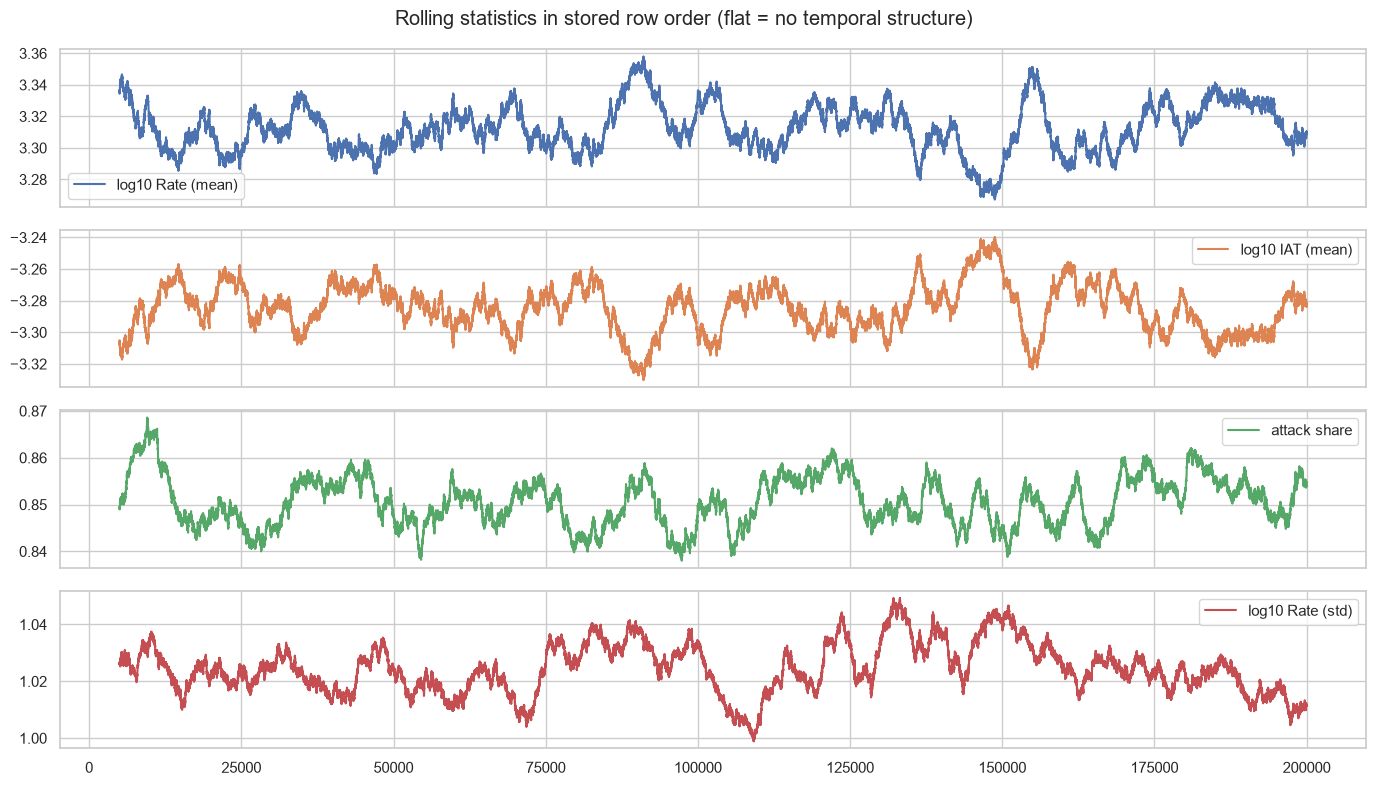

ADF log10 Rate : stat=-156.74  p=0  -> stationary
ADF log10 IAT  : stat=-156.63  p=0  -> stationary


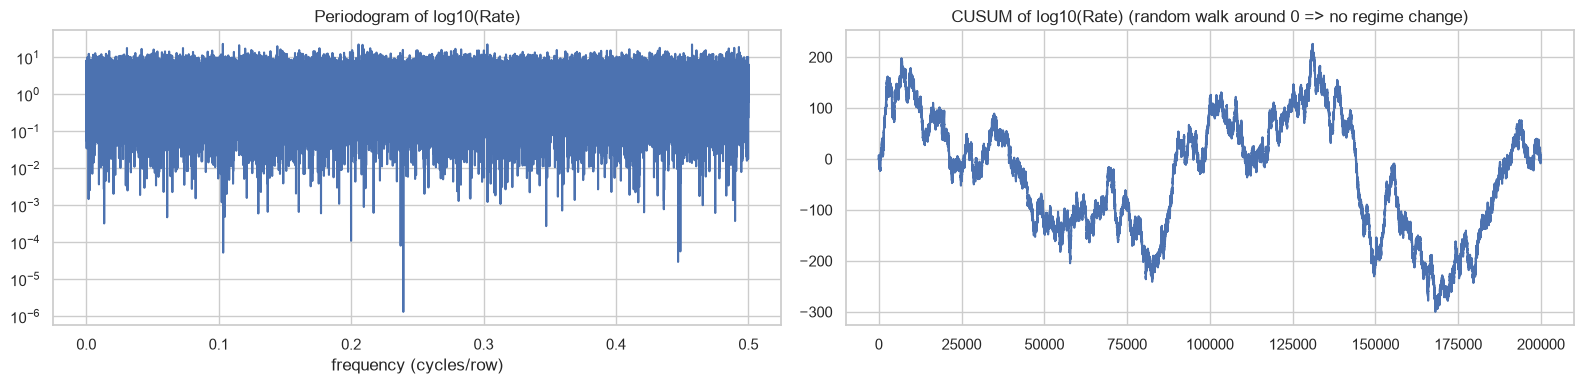

Dominant frequency 0.10313 cycles/row  (a flat spectrum / tiny peak = white noise)


In [39]:
# ---- Rolling statistics along row order (window = 5 000 rows) ----
W = 5000
roll = pd.DataFrame({"log10 Rate (mean)": pd.Series(lr).rolling(W).mean(),
                     "log10 IAT (mean)": pd.Series(li).rolling(W).mean(),
                     "attack share": pd.Series(yb).rolling(W).mean(),
                     "log10 Rate (std)": pd.Series(lr).rolling(W).std()})
roll.plot(subplots=True, figsize=(14, 8), title="Rolling statistics in stored row order (flat = no temporal structure)")
plt.tight_layout(); plt.show()

# ---- ADF stationarity ----
for nm, x in [("log10 Rate", lr), ("log10 IAT", li)]:
    stat, pv, *_ = adfuller(x[:50_000], autolag="AIC")
    print(f"ADF {nm:11s}: stat={stat:.2f}  p={pv:.4g}  ->", "stationary" if pv < 0.05 else "non-stationary")

# ---- Periodogram: is there a hidden period? ----
from scipy.signal import periodogram
f, Pxx = periodogram(lr[:100_000] - lr[:100_000].mean())
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].semilogy(f[1:], Pxx[1:]); ax[0].set_title("Periodogram of log10(Rate)"); ax[0].set_xlabel("frequency (cycles/row)")
# ---- CUSUM change-point view ----
cus = np.cumsum(lr - lr.mean()); ax[1].plot(cus); ax[1].set_title("CUSUM of log10(Rate) (random walk around 0 => no regime change)")
plt.tight_layout(); plt.show()
peak = f[1:][np.argmax(Pxx[1:])]
print(f"Dominant frequency {peak:.5f} cycles/row  (a flat spectrum / tiny peak = white noise)")

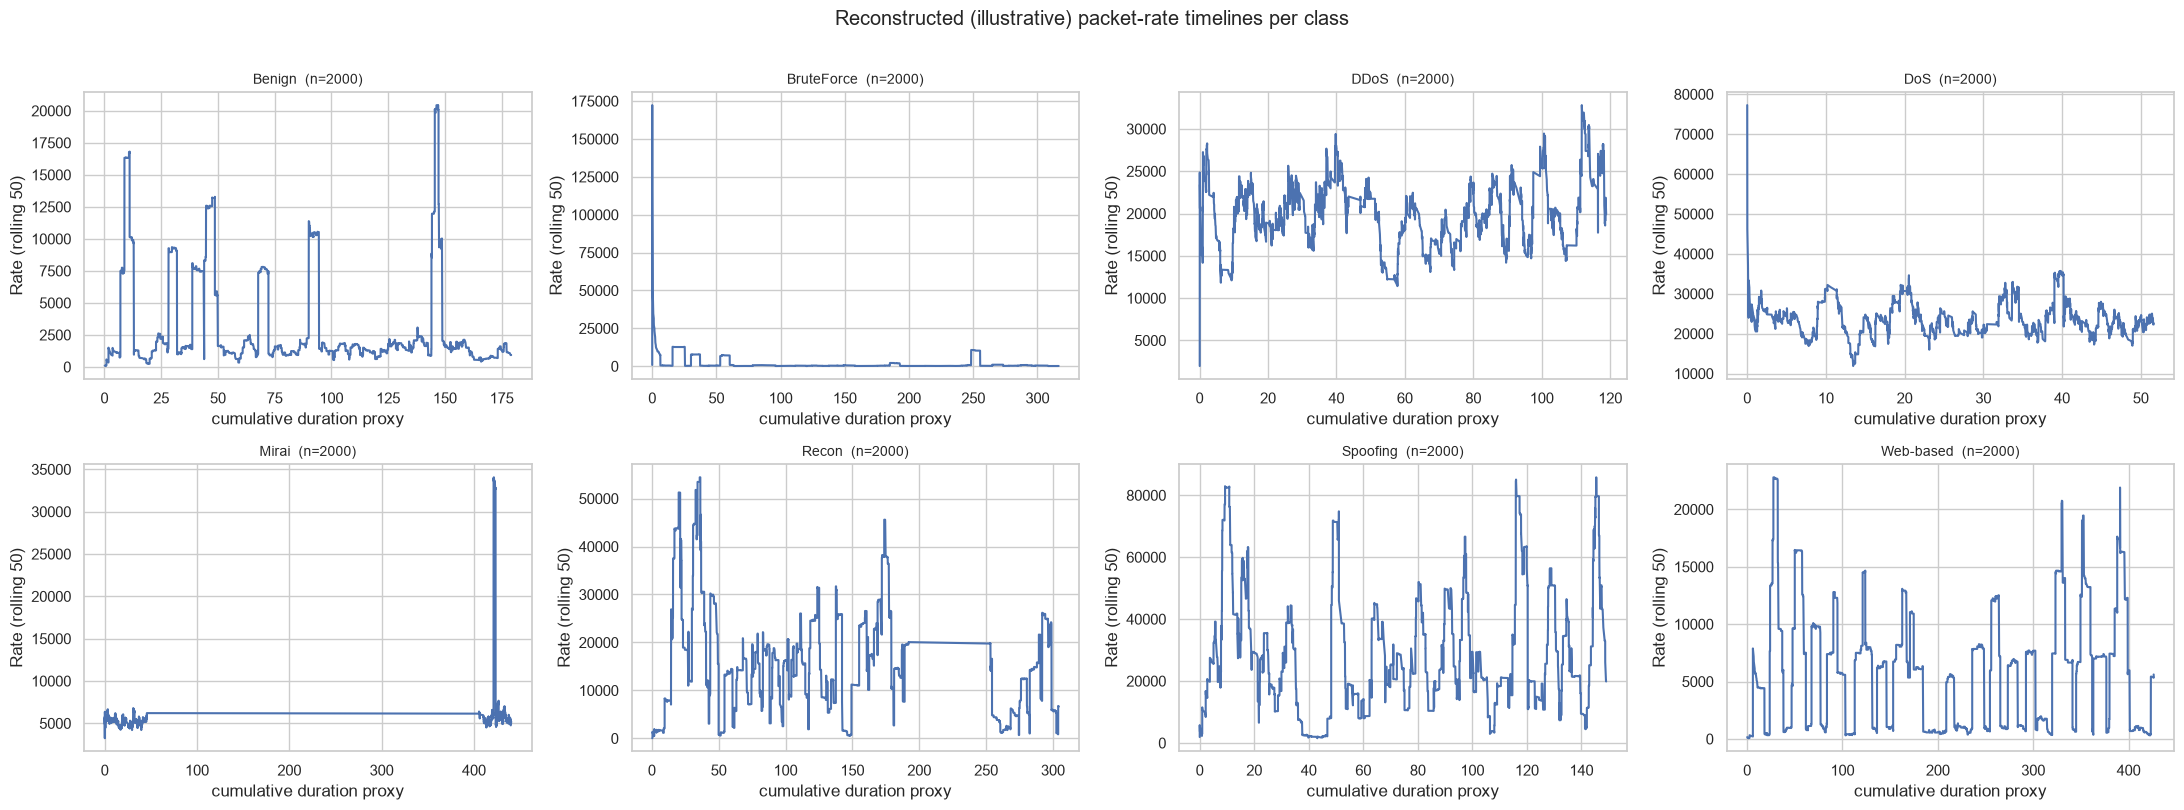

In [40]:
# ---- Illustrative reconstructed timeline per attack class (cumulative sum of duration_proxy) ----
# NOTE: this is a SIMULATION built from IAT*Number, NOT a real capture timeline.
N_T = 2000
fig, axes = plt.subplots(2, 4, figsize=(22, 8), sharey=False)
for ax, (cls, g) in zip(axes.ravel(), df.groupby("attack_class")):
    g = g.head(N_T)
    t = np.cumsum(g["duration_proxy"].values)
    ax.plot(t, g["Rate"].rolling(50, min_periods=1).mean().values)
    ax.set_title(f"{cls}  (n={len(g)})", fontsize=10); ax.set_xlabel("cumulative duration proxy"); ax.set_ylabel("Rate (rolling 50)")
for ax in axes.ravel()[df["attack_class"].nunique():]:
    ax.axis("off")
plt.suptitle("Reconstructed (illustrative) packet-rate timelines per class", y=1.01); plt.tight_layout(); plt.show()

## 11. Advanced analysis

### 11.1 PCA

Components for 90% / 95% / 99% variance: 18 / 22 / 27  (out of 39)


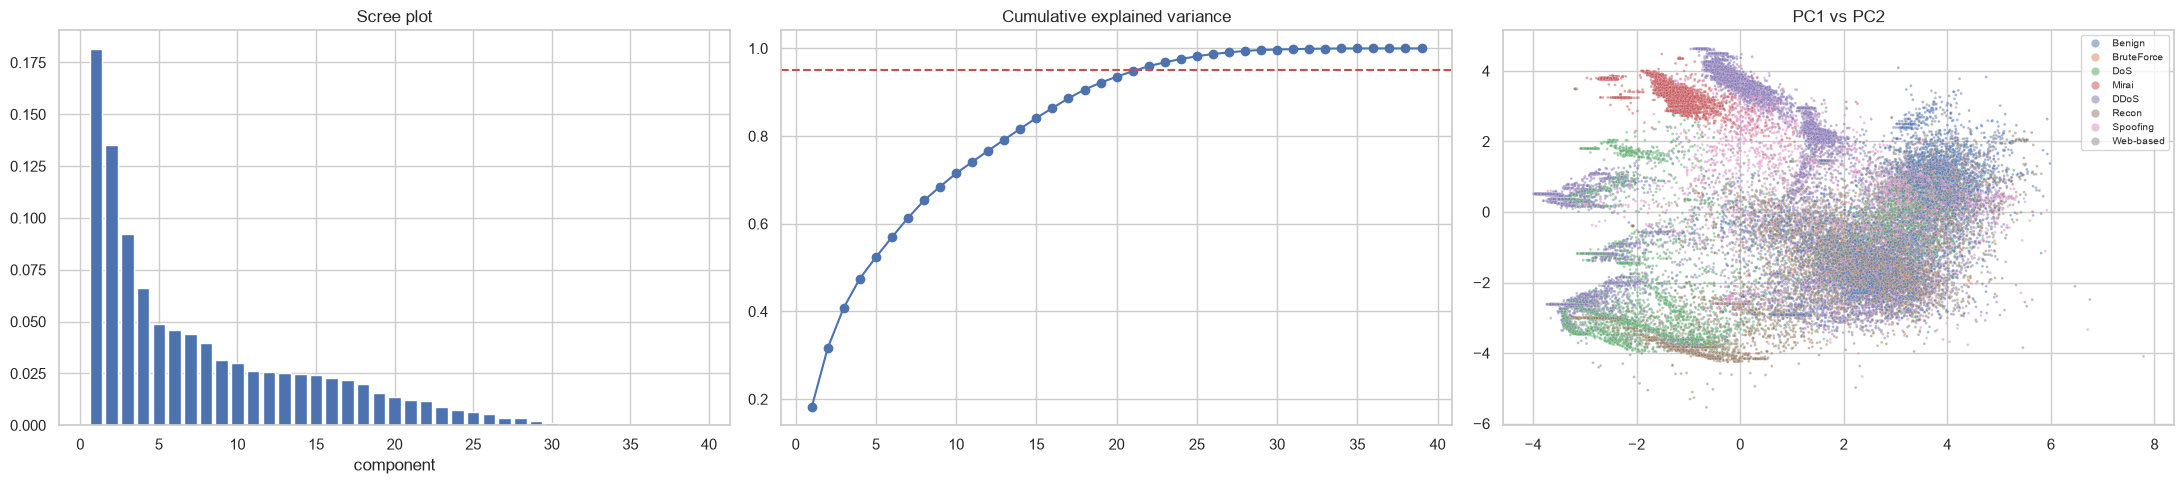

,PC1,PC2,PC3,PC4,PC5
ack_flag_number,0.320766,-0.132087,-0.0895472,0.0922032,-0.0509694
Std,0.30794,0.163374,-0.0633573,-0.0914545,-0.0491667
Variance,0.307819,0.164542,-0.0634018,-0.0912112,-0.049486
Rate,-0.289084,0.00430639,-0.164297,-0.0116075,-0.0832637
ack_count,0.273672,-0.104599,-0.199598,-0.112907,0.0231453
Max,0.264209,0.260165,-0.133474,-0.0779664,-0.0123911
HTTPS,0.256912,-0.0624915,0.063147,0.259476,-0.175749
psh_flag_number,0.256716,-0.0798364,0.025028,0.074838,0.0162513
Number,-0.252169,0.120353,-0.193892,-0.233671,0.0340132
Time_To_Live,0.186438,-0.0776549,0.0449867,0.293374,-0.116331


In [41]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

var_cols = [c for c in FEATURES if df[c].std() > 0]
S = df.sample(min(SAMPLE_N, len(df)), random_state=SEED)
scaler = StandardScaler().fit(slog(S[var_cols].values))
Xp = scaler.transform(slog(S[var_cols].values))
pca = PCA().fit(Xp)
evr = pca.explained_variance_ratio_; cum = np.cumsum(evr)
n95 = int(np.searchsorted(cum, 0.95) + 1); n99 = int(np.searchsorted(cum, 0.99) + 1)
print(f"Components for 90% / 95% / 99% variance: {int(np.searchsorted(cum, .90)+1)} / {n95} / {n99}  (out of {len(var_cols)})")
report["pca_components_95pct"] = n95

fig, ax = plt.subplots(1, 3, figsize=(22, 5))
ax[0].bar(range(1, len(evr) + 1), evr); ax[0].set_title("Scree plot"); ax[0].set_xlabel("component")
ax[1].plot(range(1, len(cum) + 1), cum, marker="o"); ax[1].axhline(.95, color="r", ls="--"); ax[1].set_title("Cumulative explained variance")
Z = pca.transform(Xp)[:, :2]
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=S["attack_class"].values, s=4, alpha=.5, ax=ax[2]); ax[2].set_title("PC1 vs PC2"); ax[2].legend(markerscale=3, fontsize=7)
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(pca.components_[:5].T, index=var_cols, columns=[f"PC{i}" for i in range(1, 6)])
display(loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(15))

### 11.2 t-SNE (non-linear embedding)

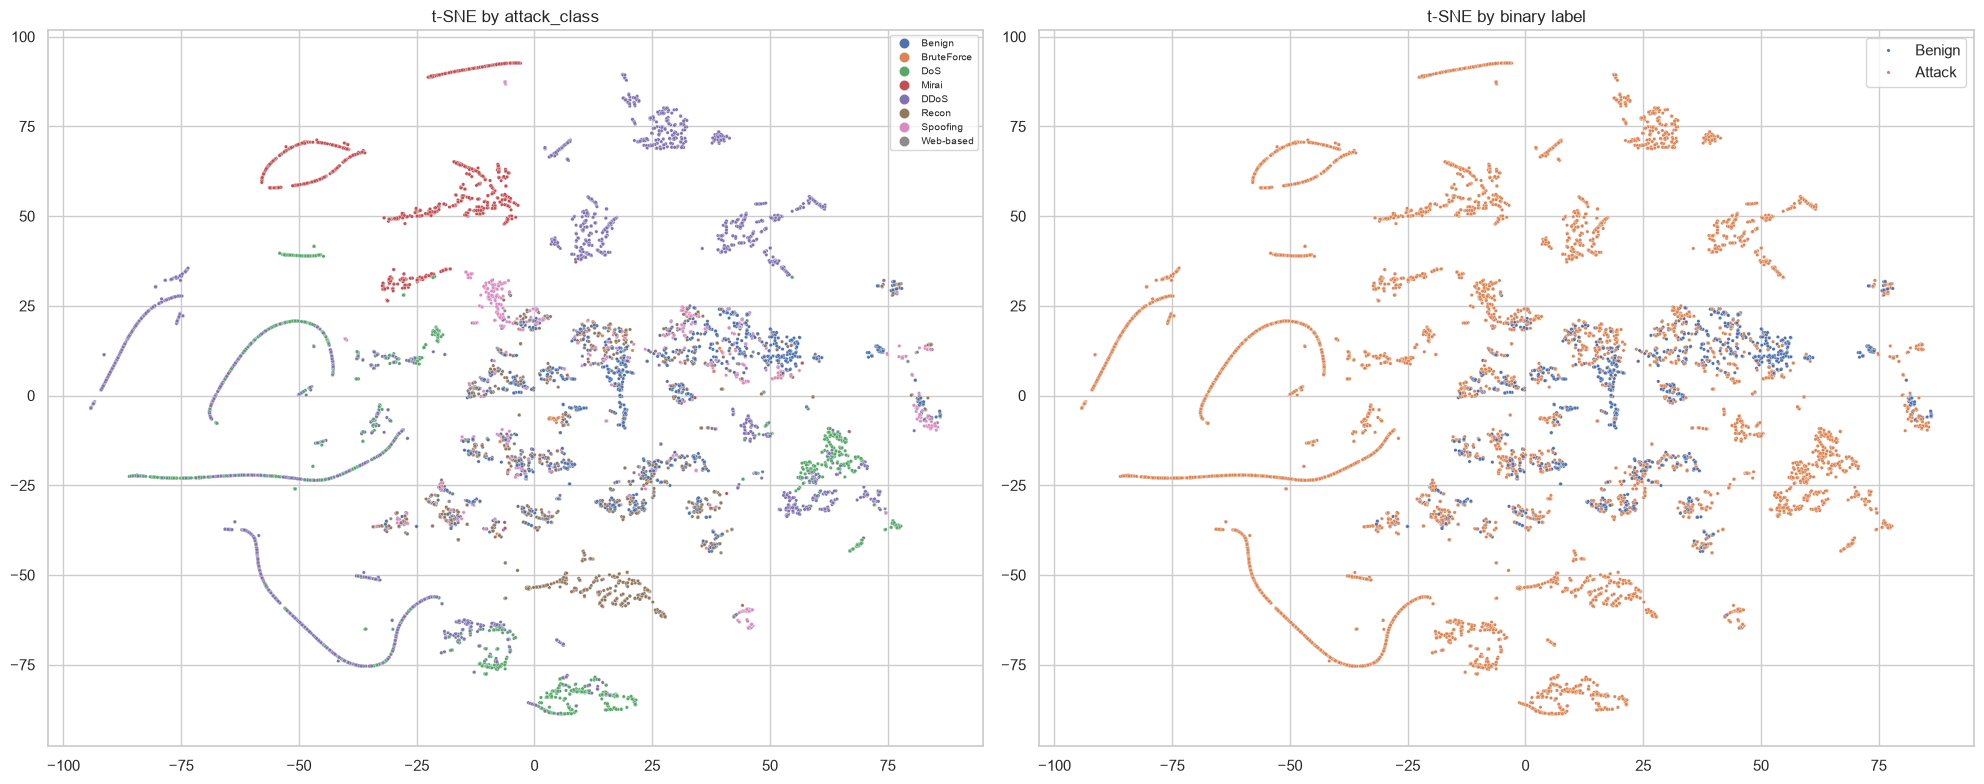

In [42]:
from sklearn.manifold import TSNE
T = df.sample(min(TSNE_N, len(df)), random_state=SEED)
Xt = PCA(n_components=min(20, len(var_cols)), random_state=SEED).fit_transform(StandardScaler().fit_transform(slog(T[var_cols].values)))
emb = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Xt)
fig, ax = plt.subplots(1, 2, figsize=(20, 8))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=T["attack_class"].values, s=6, ax=ax[0]); ax[0].set_title("t-SNE by attack_class"); ax[0].legend(markerscale=3, fontsize=7)
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=T["label"].map({0: "Benign", 1: "Attack"}).values, s=6, ax=ax[1]); ax[1].set_title("t-SNE by binary label")
plt.tight_layout(); plt.show()

### 11.3 Clustering (K-Means, silhouette, hierarchical)

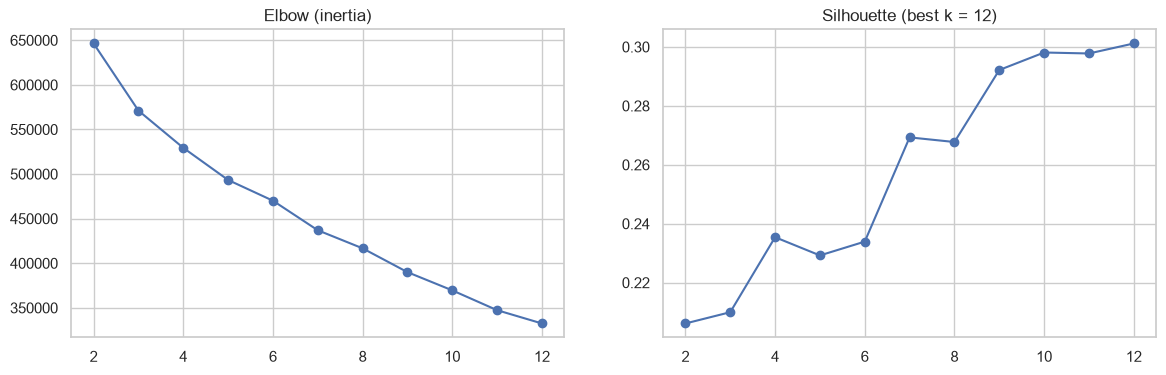

K-Means with k=8: ARI vs attack_class = 0.217 | NMI = 0.369


attack_class,Benign,BruteForce,DDoS,DoS,Mirai,Recon,Spoofing,Web-based
cluster,,,,,,,,
0,1126,30,1490,34,20,397,528,71
1,0,0,125,447,0,472,2,1
2,2,0,802,97,2247,13,245,3
3,3,0,559,465,2,22,2,6
4,0,1,1457,597,0,249,0,0
5,9,2,2214,1286,0,10,69,3
6,192,28,13,0,6,299,100,55
7,1684,128,54,5,2,1528,574,224


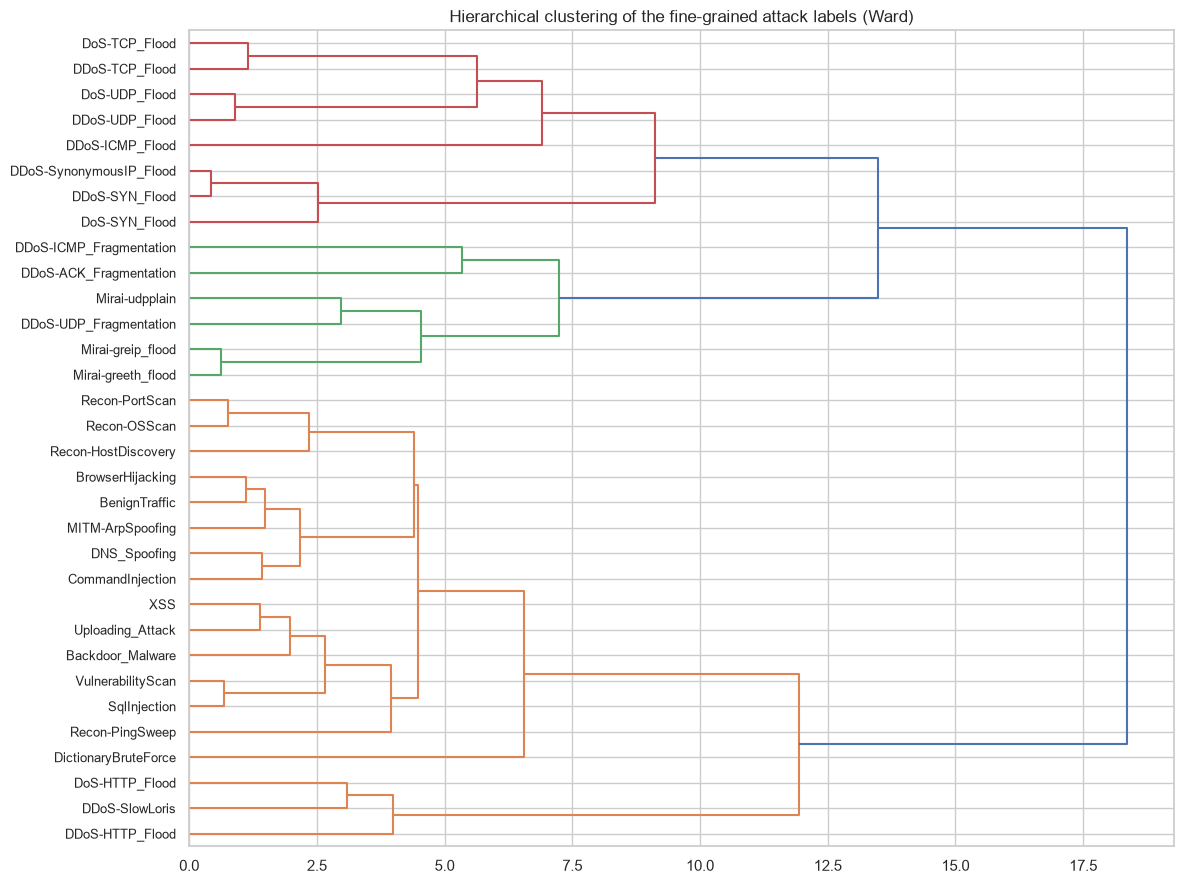

In [43]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import linkage, dendrogram

Xk = Xp[:20_000]; yk = S["attack_class"].values[:20_000]
ks = range(2, 13); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(Xk)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xk, km.labels_, sample_size=5000, random_state=SEED))
best_k = list(ks)[int(np.argmax(sil))]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(list(ks), inertia, marker="o"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(list(ks), sil, marker="o"); ax[1].set_title(f"Silhouette (best k = {best_k})")
plt.show()

k_true = df["attack_class"].nunique()
km = KMeans(n_clusters=k_true, n_init=10, random_state=SEED).fit(Xk)
print(f"K-Means with k={k_true}: ARI vs attack_class = {adjusted_rand_score(yk, km.labels_):.3f} | NMI = {normalized_mutual_info_score(yk, km.labels_):.3f}")
display(pd.crosstab(pd.Series(km.labels_, name="cluster"), pd.Series(yk, name="attack_class")))

# hierarchical clustering of the classes themselves (how similar are attack types?)
cm = pd.DataFrame(Xp, columns=var_cols).assign(c=S["Label"].values).groupby("c").mean()
plt.figure(figsize=(12, 9)); dendrogram(linkage(cm.values, "ward"), labels=cm.index.tolist(), orientation="right", leaf_font_size=9)
plt.title("Hierarchical clustering of the fine-grained attack labels (Ward)"); plt.tight_layout(); plt.show()

### 11.4 Feature importance (4 independent methods)

,RF_impurity,mutual_info,ANOVA_F,permutation,mean_rank
Number,0.129976,0.160099,"10,336.6",0.0223143,1.5
HTTPS,0.109098,0.157538,"11,877.6",0.0219015,2
Header_Length,0.0550896,0.157107,"3,916.88",0.0112217,5
Tot sum,0.0391665,0.167187,"1,681.93",0.00352337,6.75
Time_To_Live,0.0532075,0.137761,"4,398.55",0.00487444,6.75
Max,0.0430029,0.130376,"1,609.81",0.0148253,7.75
psh_flag_number,0.0249947,0.0893921,"2,146.78",0.00207926,12.5
ack_flag_number,0.0728591,0.156875,"7,303.7",-0.00194454,12.75
Rate,0.0587467,0.0949287,309.178,0.000425131,14.25
syn_count,0.023506,0.0409729,892.361,0.00557886,14.5


[saved] outputs\11_feature_importance.csv


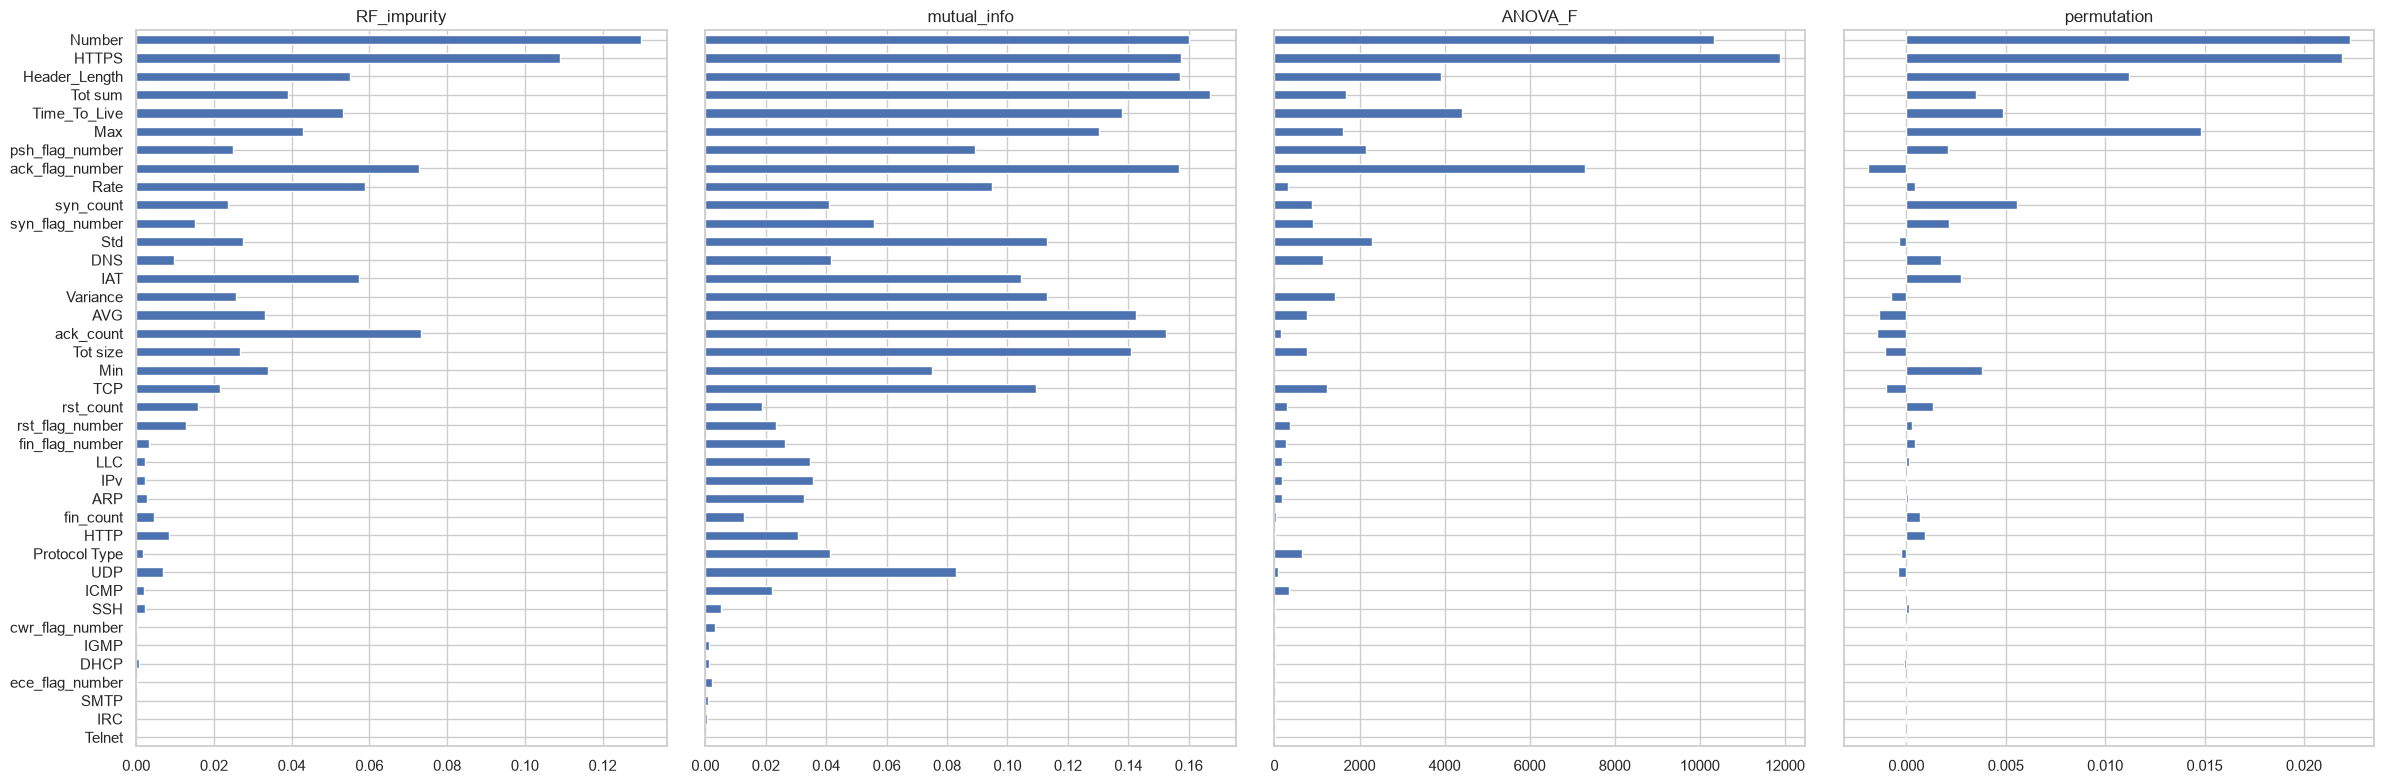

Overlap between our top-20 and the dataset card's top-20 RF list: 18/20


In [44]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.inspection import permutation_importance

train = df[df["split"] == "train"]
val_name = "validation" if "validation" in df["split"].unique() else [s for s in df["split"].unique() if s != "train"][0]
val   = df[df["split"] == val_name]
trn   = train.sample(min(MODEL_TRAIN_N, len(train)), random_state=SEED)
Xtr, ytr = trn[FEATURES].values, trn["label"].values
Xva, yva = val[FEATURES].values, val["label"].values

rf = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEED, class_weight="balanced_subsample", min_samples_leaf=2).fit(Xtr, ytr)
imp_rf = pd.Series(rf.feature_importances_, index=FEATURES, name="RF_impurity")

sub = trn.sample(min(30_000, len(trn)), random_state=SEED)
imp_mi = pd.Series(mutual_info_classif(sub[FEATURES].values, sub["label"].values, random_state=SEED), index=FEATURES, name="mutual_info")
imp_f  = pd.Series(np.nan_to_num(f_classif(sub[FEATURES].values, sub["label"].values)[0]), index=FEATURES, name="ANOVA_F")
vs = val.sample(min(10_000, len(val)), random_state=SEED)
pi = permutation_importance(rf, vs[FEATURES].values, vs["label"].values, n_repeats=5, random_state=SEED, n_jobs=-1, scoring="f1")
imp_pi = pd.Series(pi.importances_mean, index=FEATURES, name="permutation")

imp = pd.concat([imp_rf, imp_mi, imp_f, imp_pi], axis=1)
rank = imp.rank(ascending=False); imp["mean_rank"] = rank.mean(axis=1)
imp = imp.sort_values("mean_rank")
display(imp)
save_table(imp, "11_feature_importance")

fig, axes = plt.subplots(1, 4, figsize=(24, 8), sharey=True)
order = imp.index[::-1]
for ax, c in zip(axes, ["RF_impurity", "mutual_info", "ANOVA_F", "permutation"]):
    imp.loc[order, c].plot.barh(ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

CARD_TOP20 = ["HTTPS","Number","Time_To_Live","Max","ack_flag_number","Rate","IAT","ack_count","Header_Length","Min","Variance","psh_flag_number","Tot sum","Std","Tot size","syn_count","AVG","rst_flag_number","DNS","rst_count"]
ours = imp.index[:20].tolist()
print(f"Overlap between our top-20 and the dataset card's top-20 RF list: {len(set(ours) & set(CARD_TOP20))}/20")
report["top10_features"] = imp.index[:10].tolist()

### 11.5 Binary classification (Benign vs Attack) — model errors = "failures" of a detector

,accuracy,balanced_acc,precision,recall,f1,MCC,ROC_AUC,PR_AUC,FP,FN,FPR,FNR,error_rate
LogisticRegression,0.83302,0.889643,0.993613,0.808987,0.891845,0.601531,0.935858,0.989121,594,"21,820",0.0297015,0.191013,0.16698
RandomForest,0.922999,0.888452,0.970859,0.937662,0.953972,0.723073,0.970017,0.99492,"3,215","7,121",0.160758,0.0623375,0.077001
HistGradientBoosting,0.9265,0.860481,0.958921,0.954523,0.956717,0.713336,0.970832,0.995072,"4,671","5,195",0.233562,0.0454772,0.0734996


[saved] outputs\11_binary_model_results.csv


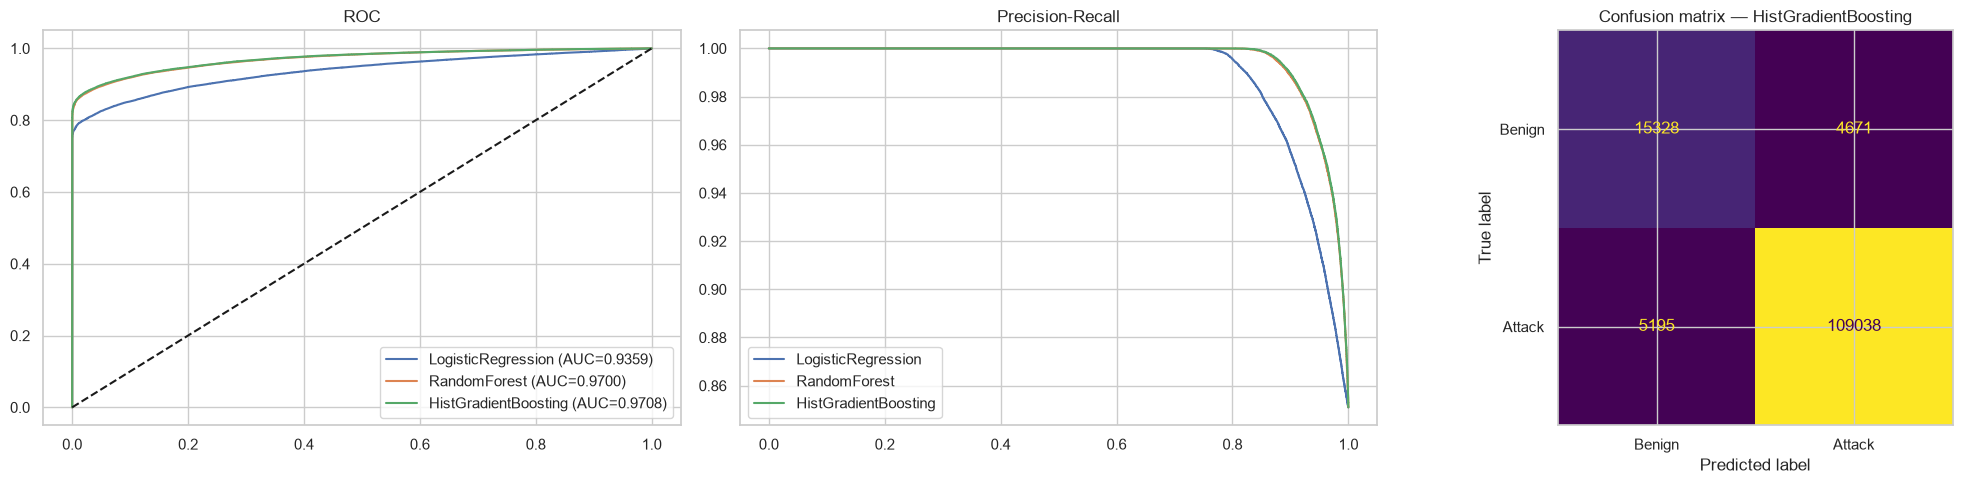

In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef,
                             roc_auc_score, average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
                             classification_report, ConfusionMatrixDisplay)

models = {
    "LogisticRegression": make_pipeline(FunctionTransformer(slog), StandardScaler(), LogisticRegression(max_iter=500, class_weight="balanced")),
    "RandomForest": rf,
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=200, random_state=SEED),
}
res, curves = {}, {}
for name, m in models.items():
    if name != "RandomForest":
        m.fit(Xtr, ytr)
    proba = m.predict_proba(Xva)[:, 1]; pred = (proba >= .5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yva, pred).ravel()
    res[name] = dict(accuracy=accuracy_score(yva, pred), balanced_acc=balanced_accuracy_score(yva, pred), precision=precision_score(yva, pred),
                     recall=recall_score(yva, pred), f1=f1_score(yva, pred), MCC=matthews_corrcoef(yva, pred),
                     ROC_AUC=roc_auc_score(yva, proba), PR_AUC=average_precision_score(yva, proba),
                     FP=fp, FN=fn, FPR=fp / (fp + tn), FNR=fn / (fn + tp), error_rate=(fp + fn) / len(yva))
    curves[name] = (yva, proba, pred)
bin_res = pd.DataFrame(res).T
display(bin_res)
save_table(bin_res, "11_binary_model_results")
report["binary_models"] = bin_res[["f1", "ROC_AUC", "error_rate", "FPR", "FNR"]].round(5).to_dict("index")

fig, ax = plt.subplots(1, 3, figsize=(21, 5))
for name, (yt, pr, pd_) in curves.items():
    fpr, tpr, _ = roc_curve(yt, pr); ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yt, pr):.4f})")
    p_, r_, _ = precision_recall_curve(yt, pr); ax[1].plot(r_, p_, label=name)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC"); ax[0].legend(); ax[1].set_title("Precision-Recall"); ax[1].legend()
best = bin_res["f1"].idxmax()
ConfusionMatrixDisplay.from_predictions(curves[best][0], curves[best][2], display_labels=["Benign", "Attack"], ax=ax[2], colorbar=False); ax[2].set_title(f"Confusion matrix — {best}")
plt.tight_layout(); plt.show()

### 11.6 Multi-class classification (8 attack classes and 34 fine-grained labels) + error analysis

              precision    recall  f1-score   support

      Benign     0.7098    0.8171    0.7597     19999
  BruteForce     0.8824    0.2674    0.4105      1290
        DDoS     0.8925    0.9339    0.9127     45186
         DoS     0.8334    0.7480    0.7884     19969
       Mirai     1.0000    0.9964    0.9982     14947
       Recon     0.7202    0.7330    0.7265     20222
    Spoofing     0.9253    0.8598    0.8914     10077
   Web-based     0.7051    0.2164    0.3311      2542

    accuracy                         0.8400    134232
   macro avg     0.8336    0.6965    0.7273    134232
weighted avg     0.8413    0.8400    0.8354    134232



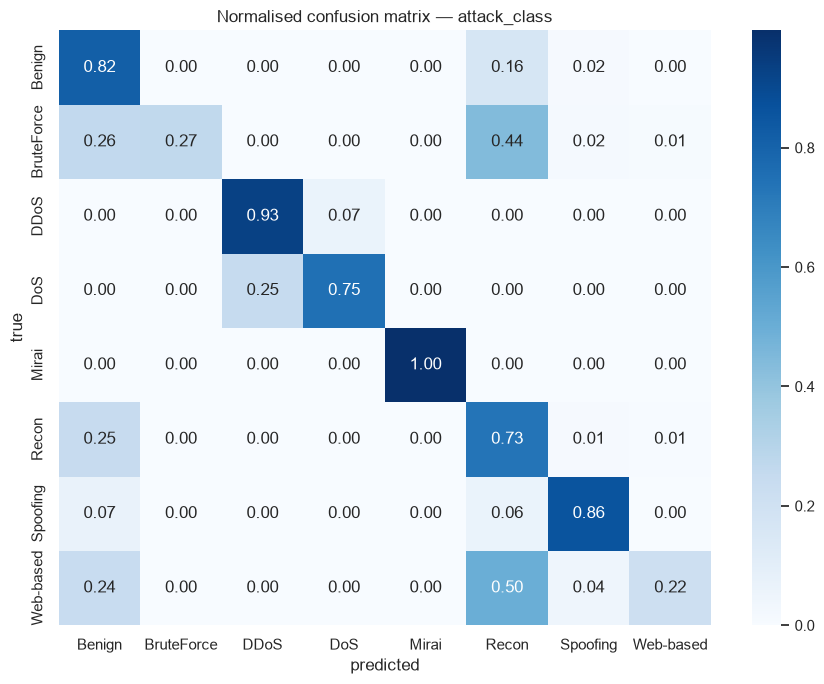

In [46]:
rf8 = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED, min_samples_leaf=2).fit(Xtr, trn["attack_class"].values)
p8 = rf8.predict(Xva); y8 = val["attack_class"].values
print(classification_report(y8, p8, digits=4))
cm8 = confusion_matrix(y8, p8, labels=rf8.classes_, normalize="true")
plt.figure(figsize=(9, 7)); sns.heatmap(cm8, annot=True, fmt=".2f", cmap="Blues", xticklabels=rf8.classes_, yticklabels=rf8.classes_)
plt.title("Normalised confusion matrix — attack_class"); plt.ylabel("true"); plt.xlabel("predicted"); plt.tight_layout(); plt.show()
report["attack_class_macro_f1"] = round(float(f1_score(y8, p8, average="macro")), 4)
report["attack_class_accuracy"] = round(float(accuracy_score(y8, p8)), 4)

Fine-grained (32 labels): accuracy=0.7628  macro-F1=0.6221  weighted-F1=0.7459

Hardest labels (lowest F1):


,F1
Uploading_Attack,0.0136054
Recon-PingSweep,0.0526316
XSS,0.0590909
SqlInjection,0.0751342
Backdoor_Malware,0.104972
Recon-OSScan,0.200877
CommandInjection,0.371274
BrowserHijacking,0.372796
VulnerabilityScan,0.376671
Recon-PortScan,0.400479



Top 15 confusions:


,true,predicted,rows
801,Recon-OSScan,BenignTraffic,2698
961,VulnerabilityScan,BenignTraffic,2532
266,DDoS-SYN_Flood,DDoS-SynonymousIP_Flood,2075
865,Recon-PortScan,BenignTraffic,2024
620,DoS-UDP_Flood,DDoS-UDP_Flood,1549
587,DoS-TCP_Flood,DDoS-TCP_Flood,1441
827,Recon-OSScan,Recon-PortScan,1085
328,DDoS-SynonymousIP_Flood,DDoS-SYN_Flood,1072
403,DDoS-UDP_Flood,DoS-UDP_Flood,1048
769,Recon-HostDiscovery,BenignTraffic,1007


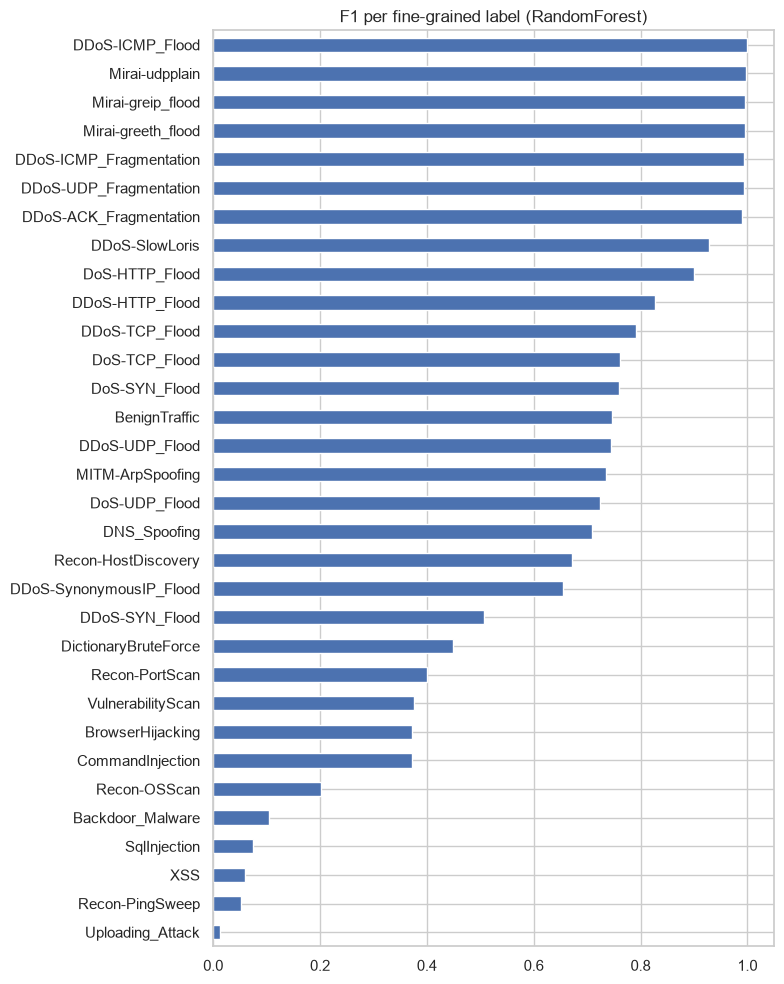

In [47]:
rf34 = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED, min_samples_leaf=2).fit(Xtr, trn["Label"].values)
p34 = rf34.predict(Xva); y34 = val["Label"].values
f1s = pd.Series(f1_score(y34, p34, average=None, labels=rf34.classes_), index=rf34.classes_, name="F1").sort_values()
print(f"Fine-grained ({len(rf34.classes_)} labels): accuracy={accuracy_score(y34, p34):.4f}  macro-F1={f1_score(y34, p34, average='macro'):.4f}  weighted-F1={f1_score(y34, p34, average='weighted'):.4f}")
print("\nHardest labels (lowest F1):"); display(f1s.head(12).to_frame())

# most frequent confusions
conf = pd.crosstab(pd.Series(y34, name="true"), pd.Series(p34, name="predicted")).stack().rename("rows").reset_index()
conf = conf[conf["true"] != conf["predicted"]].sort_values("rows", ascending=False).head(15)
print("\nTop 15 confusions:"); display(conf)
f1s.plot.barh(figsize=(8, 10), title="F1 per fine-grained label (RandomForest)"); plt.tight_layout(); plt.show()
report["label34_macro_f1"] = round(float(f1_score(y34, p34, average="macro")), 4)
report["hardest_labels"] = f1s.head(5).round(4).to_dict()

### 11.7 Cross-validation (robustness of the result)

In [48]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv_s = df.sample(min(60_000, len(df)), random_state=SEED)
cv = cross_validate(RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED, class_weight="balanced_subsample"),
                    cv_s[FEATURES].values, cv_s["label"].values, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                    scoring=["accuracy", "f1", "roc_auc"], n_jobs=1)
cv_df = pd.DataFrame({k: v for k, v in cv.items() if k.startswith("test_")}).rename(columns=lambda c: c.replace("test_", ""))
display(cv_df.describe().loc[["mean", "std", "min", "max"]])
report["cv5_f1_mean"] = round(float(cv_df["f1"].mean()), 5); report["cv5_f1_std"] = round(float(cv_df["f1"].std()), 5)

,accuracy,f1,roc_auc
mean,0.920733,0.953733,0.96591
std,0.00231945,0.00135671,0.0015523
min,0.9185,0.952367,0.963484
max,0.924583,0.955963,0.967175


## 12. Final summary & export

In [49]:
print("=" * 78)
print("                       CIC-IoT-2023 — FINAL SUMMARY")
print("=" * 78)
print(f"Rows x features            : {report['n_rows']:,} x {report['n_features']}  ({report['memory_mb']} MB in RAM)")
print(f"Attack / Benign            : {report['attack_rows']:,} / {report['benign_rows']:,}  ({report['attack_pct']}% attack)")
print(f"Classes                    : {report['n_attack_classes']} groups, {report['n_labels']} fine-grained labels (smallest: {report['smallest_label']} = {report['smallest_label_rows']:,} rows)")
print(f"Rows with hard defect      : {report['rows_with_hard_defect']:,} ({report['rows_with_hard_defect_pct']}%)")
print(f"Exact duplicate rows       : {report['duplicate_rows']:,} ({report['duplicate_rows_pct']}%)")
print(f"Rows in label conflicts    : {report['label_conflict_rows']:,} ({report['label_conflict_rows_pct']}%)")
print(f"IAT  min / median / max    : {report['IAT_min']:.3g} / {report['IAT_median']:.3g} / {report['IAT_max']:.3g}")
print(f"Rate min / median / max    : {report['Rate_min']:.3g} / {report['Rate_median']:.3g} / {report['Rate_max']:.3g}")
print(f"Row-order runs test p      : {report['runs_test_p']}  (p > 0.01 => shuffled, no real temporal order)")
print(f"Max PSI between splits     : {report['max_psi_between_splits']}")
print(f"PCA comps for 95% variance : {report['pca_components_95pct']} / {report['n_features']}")
print(f"Top-10 features            : {report['top10_features']}")
print(f"Binary RF F1 / error rate  : {report['binary_models']['RandomForest']['f1']} / {report['binary_models']['RandomForest']['error_rate']}")
print(f"8-class macro-F1           : {report['attack_class_macro_f1']} | 34-label macro-F1: {report['label34_macro_f1']}")
print(f"5-fold CV F1 (binary RF)   : {report['cv5_f1_mean']} +/- {report['cv5_f1_std']}")
print("=" * 78)

with open(os.path.join(OUT, "analysis_summary.json"), "w") as fh:
    json.dump(report, fh, indent=2, default=str)
print("Summary JSON saved to", os.path.join(OUT, "analysis_summary.json"))
print("Exported files:", sorted(os.listdir(OUT)))

                       CIC-IoT-2023 — FINAL SUMMARY
Rows x features            : 1,342,314 x 39  (473.6 MB in RAM)
Attack / Benign            : 1,142,326 / 199,988  (85.101% attack)
Classes                    : 8 groups, 32 fine-grained labels (smallest: Uploading_Attack = 1,252 rows)
Rows with hard defect      : 1 (0.0001%)
Exact duplicate rows       : 115,597 (8.612%)
Rows in label conflicts    : 114,702 (8.545%)
IAT  min / median / max    : -0.00647 / 0.000438 / 4.67e+04
Rate min / median / max    : 2.14e-05 / 2.39e+03 / 6.29e+06
Row-order runs test p      : 0.36459  (p > 0.01 => shuffled, no real temporal order)
Max PSI between splits     : 0.00082
PCA comps for 95% variance : 22 / 39
Top-10 features            : ['Number', 'HTTPS', 'Header_Length', 'Tot sum', 'Time_To_Live', 'Max', 'psh_flag_number', 'ack_flag_number', 'Rate', 'syn_count']
Binary RF F1 / error rate  : 0.95397 / 0.077
8-class macro-F1           : 0.7273 | 34-label macro-F1: 0.6221
5-fold CV F1 (binary RF)   : 0.953

                      count        mean        std         min          1%          5%         25%         50%        75%       95%       99%         max      median       range        IQR      skew  kurtosis  missing   zeros_%
Header_Length   1.34231e+06     17.4995    11.1964           0           0           0           8          20         26      32.8        42          60          20          60         18 0.0287717 -0.702915        0   8.15249
Protocol Type   1.34231e+06     10.9853    11.2599           0           1           1           6           6         17        47        47          47           6          47         11   2.33269   4.79738        0   0.28056
Time_To_Live    1.34231e+06     79.6254    34.4024           0          48        59.8          64          64       80.3     155.9       231         255          64         255       16.3   2.63077   7.27032        0 0.0129627
Rate            1.34231e+06    16,151.4   50,031.3 2.14292e-05     22.6148     47.3042  

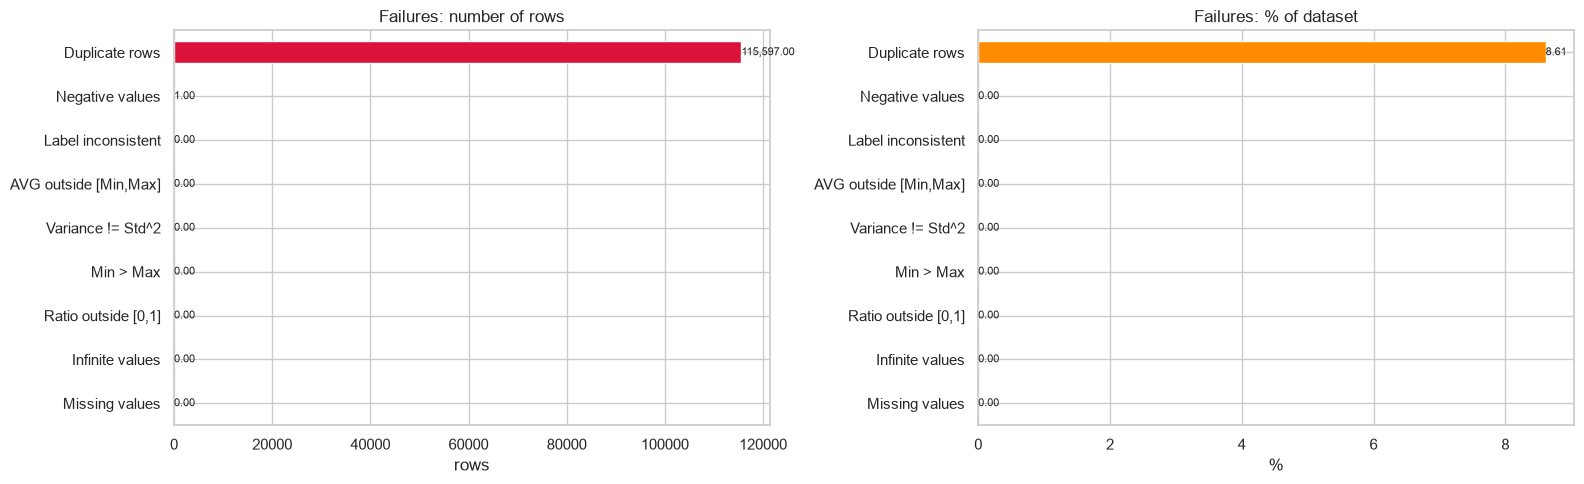

In [50]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from datasets import load_dataset

# 1) Load all splits
ds = load_dataset("lacg030175/CIC-IoT-2023", "random_3way")
df = pd.concat([ds[s].to_pandas().assign(split=s) for s in ds], ignore_index=True)

TARGETS  = ["Label", "attack_class", "label"]
FEATURES = [c for c in df.columns if c not in TARGETS + ["split"]]

# 2) Min / Max / Median / etc. for ALL features
stats = df[FEATURES].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
stats["median"] = df[FEATURES].median()
stats["range"]  = stats["max"] - stats["min"]
stats["IQR"]    = stats["75%"] - stats["25%"]
stats["skew"]   = df[FEATURES].skew()
stats["kurtosis"] = df[FEATURES].kurt()
stats["missing"]  = df[FEATURES].isna().sum()
stats["zeros_%"]  = (df[FEATURES] == 0).mean() * 100
pd.set_option("display.max_rows", 100, "display.width", 250)
print(stats)
stats.to_csv("stats_all_features.csv")

# 3) Failures (data defects)
X = df[FEATURES]
ratio_cols = [c for c in X.columns if c.endswith("_flag_number")] + \
             [c for c in ["HTTP","HTTPS","DNS","Telnet","SMTP","SSH","IRC","TCP","UDP",
                          "DHCP","ARP","ICMP","IGMP","IPv","LLC"] if c in X.columns]
failures = {
    "Missing values":          X.isna().any(axis=1).sum(),
    "Infinite values":         np.isinf(X).any(axis=1).sum(),
    "Negative values":         (X < 0).any(axis=1).sum(),
    "Ratio outside [0,1]":     ((df[ratio_cols] < 0) | (df[ratio_cols] > 1)).any(axis=1).sum(),
    "Min > Max":               (df["Min"] > df["Max"]).sum(),
    "AVG outside [Min,Max]":   ((df["AVG"] < df["Min"] - 1e-6) | (df["AVG"] > df["Max"] + 1e-6)).sum(),
    "Variance != Std^2":       (~np.isclose(df["Variance"], df["Std"]**2, rtol=1e-3, atol=1e-6)).sum(),
    "Duplicate rows":          df.duplicated(subset=FEATURES + TARGETS).sum(),
    "Label inconsistent":      ((df["label"] == 0) != (df["Label"] == "BenignTraffic")).sum(),
}
fail = pd.Series(failures, name="rows").to_frame()
fail["%"] = fail["rows"] / len(df) * 100
print(fail)

# 4) Plot of failures
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
fail["rows"].sort_values().plot.barh(ax=ax[0], color="crimson")
ax[0].set_title("Failures: number of rows"); ax[0].set_xlabel("rows")
fail["%"].sort_values().plot.barh(ax=ax[1], color="darkorange")
ax[1].set_title("Failures: % of dataset"); ax[1].set_xlabel("%")
for a in ax:
    for p in a.patches:
        a.annotate(f"{p.get_width():,.2f}", (p.get_width(), p.get_y() + p.get_height()/2),
                   va="center", ha="left", fontsize=8)
plt.tight_layout(); plt.savefig("failures.png", dpi=150); plt.show()

### Optional: one-click automatic HTML profile
```python
# %pip install ydata-profiling
# from ydata_profiling import ProfileReport
# ProfileReport(df.sample(50_000, random_state=42), minimal=True).to_file("outputs/profile.html")
```